# Stroke Generation Model

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sys
import os
sys.path.append(os.path.join(os.getcwd(), ".."))
from framework.Spatial.BezierOptimization import BezierOptimization
from framework.Temporal.Stroke import Stroke
import yaml
from scipy.signal import find_peaks
from scipy.special import erf
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.distributions import Categorical, MultivariateNormal
from torch.utils.data import Dataset, DataLoader

## Stroke

In [2]:
STROKE_TIME_COLS = ['mu', 'sigma', 't0']
STROKE_GEOM_COLS = ['delta_p', 'u_e', 'lambda_e', 'u_s', 'lambda_s']
ARRAY_COLS = ['delta_p', 'u_s', 'u_e']
DATABASE_ROOT = os.path.join(os.getcwd().split('src')[0], 'reconstructed_csv')
EPS = 1e-12


# ---- network I/O definition ----
# Onset of the first stroke of every recording [s]. It is the origin of the time axis of a generated task:
# the later onsets are T0_FIRST plus the cumulative sum of the delays dt0.
T0_FIRST = 0.2

# Outputs of the stroke network. Every stroke is expressed from its own origin: it starts at zero.
# dt0 is the delay between the onset of the stroke and the onset of the previous stroke of the same recording;
# the first stroke of a recording has dt0 = T0_FIRST (a constant, not data).
TARGET_KEYS = ["dt0", "mu", "sigma", "lambda_s", "u_s", "lambda_e", "u_e", "delta_p"]
DT0_INDEX = TARGET_KEYS.index("dt0")
# Previous-stroke input = every target EXCEPT delta_p (a stroke never knows where the previous one ended).
PREV_KEYS = [f"prev_{k}" for k in TARGET_KEYS if k != "delta_p"]
# u_s / lambda_s are outputs like every other parameter and are taken from the data as they are:
# nothing is inherited from the previous stroke (the network sees prev_u_e / prev_lambda_e as inputs).

GEOM_SHARED_KEYS = ("wp", "wp_n", "delta_p")        # same zero-mean isotropic scale (see compute_stats)
UNIT_VECTOR_KEYS = ("u_s", "u_e")                   # unit vectors: zero mean and one isotropic scale (prev_u_* reuse it)
STAT_KEYS = ["wp", "wp_n"] + TARGET_KEYS
DATASET_KEYS = ["wp", "wp_n", "is_first"] + TARGET_KEYS + PREV_KEYS

## Nework Architecture

### Mixture Density Network Head

In [3]:
class MixtureDensityNetwork(nn.Module):
    """
    MDN head with Gaussian components, full (lower Cholesky factor) or diagonal covariance.
    Outputs: means [B, K, D], lower-triangular scale factors [B, K, D, D] (diagonal matrices for diagonal
    covariances), mixing logits [B, K].
    """

    def __init__(self, input_dim, output_dim, num_components, hidden_dim=128, min_diag=1e-3, covariance="full"):
        super().__init__()
        if covariance not in ("full", "diagonal"):
            raise ValueError("covariance must be 'full' or 'diagonal'")
        self.input_dim = input_dim
        self.output_dim = output_dim
        self.num_components = num_components
        self.hidden_dim = hidden_dim
        self.min_diag = min_diag
        self.covariance = covariance
        self.num_tril = output_dim * (output_dim + 1) // 2
        # raw scale outputs of one component: the Cholesky entries (row-major lower triangle) or the diagonal
        self.num_scale = self.num_tril if covariance == "full" else output_dim

        rows, cols = torch.tril_indices(output_dim, output_dim)
        self.register_buffer("tril_rows", rows, persistent=False)
        self.register_buffer("tril_cols", cols, persistent=False)
        self.register_buffer("diag_mask", rows == cols, persistent=False)

        self.hidden_layer = nn.Linear(input_dim, hidden_dim)
        self.weights_layer = nn.Linear(hidden_dim, num_components)  # mixing logits
        self.means_layer = nn.Linear(hidden_dim, num_components * output_dim)
        self.scale_layer = nn.Linear(hidden_dim, num_components * self.num_scale)

    def set_weights(self, target_samples: torch.Tensor, sigma_weight_scale: float = 0.1):
        """
        Initialization. `target_samples` [N, D] should already be standardized.
        Means are spread over the target range; each scale factor starts as diag(std_d)
        (zero off-diagonal entries for full covariances).
        """
        nn.init.kaiming_uniform_(self.hidden_layer.weight, nonlinearity="relu")
        nn.init.zeros_(self.hidden_layer.bias)

        nn.init.xavier_uniform_(self.weights_layer.weight)
        nn.init.xavier_uniform_(self.means_layer.weight)
        nn.init.xavier_uniform_(self.scale_layer.weight)

        t_min = target_samples.min(dim=0).values  # [D]
        t_max = target_samples.max(dim=0).values  # [D]
        mean_bias = torch.empty(self.num_components, self.output_dim)
        for k in range(self.num_components):
            mean_bias[k] = (t_min + (t_max - t_min) * (k + 0.5) / self.num_components).cpu()

        with torch.no_grad():
            self.means_layer.bias.copy_(mean_bias.reshape(-1))
            self.scale_layer.weight.mul_(sigma_weight_scale)

            # inverse softplus so that diag(L) starts at the per-dimension data std
            data_std = target_samples.std(dim=0).to(self.scale_layer.bias)
            init_diag = (data_std - self.min_diag).clamp_min(1e-3)
            raw_diag = torch.log(torch.expm1(init_diag))
            bias = torch.zeros(self.num_components, self.num_scale).to(self.scale_layer.bias)
            if self.covariance == "full":
                bias[:, self.diag_mask] = raw_diag
            else:
                bias[:] = raw_diag
            self.scale_layer.bias.copy_(bias.reshape(-1))

    def _build_scale_tril(self, raw: torch.Tensor) -> torch.Tensor:
        """raw [B, K, num_scale] -> lower-triangular L [B, K, D, D] with positive diagonal."""
        if self.covariance == "diagonal":
            return torch.diag_embed(F.softplus(raw) + self.min_diag)
        batch = raw.size(0)
        dim = self.output_dim
        tril = raw.new_zeros(batch, self.num_components, dim, dim)
        tril[..., self.tril_rows, self.tril_cols] = raw
        diag = F.softplus(tril.diagonal(dim1=-2, dim2=-1)) + self.min_diag
        return tril.tril(-1) + torch.diag_embed(diag)

    def forward(self, x: torch.Tensor):
        hidden = torch.relu(self.hidden_layer(x))
        mix_logits = self.weights_layer(hidden)
        means = self.means_layer(hidden).view(-1, self.num_components, self.output_dim)
        raw = self.scale_layer(hidden).view(-1, self.num_components, self.num_scale)
        return means, self._build_scale_tril(raw), mix_logits

### Full Model Architecture

In [4]:
class GenerativeModel(nn.Module):
    """Generative model of strokes: embeddings -> LSTM -> trunk -> MDN (full or diagonal covariance)."""

    def __init__(self, input_dim, LSTM_dim, LSTM_count, output_dim,
                 mixture_components, recur_dim=None, min_diag=1e-3, mdn_hidden_dim=128, covariance="full",
                 stateful=False):
        """
        mdn_hidden_dim: width of the hidden layer of the MDN head.
        covariance: "full" (lower Cholesky factor) or "diagonal" covariance of every mixture component.
        stateful: True carries the LSTM state along the strokes of a recording (training on whole recordings and
            autoregressive generation); False starts every stroke from the zero state.
        """
        super().__init__()
        # constructor arguments, stored in the checkpoints to rebuild the same model
        self.arch = dict(
            input_dim=input_dim, LSTM_dim=LSTM_dim, LSTM_count=LSTM_count,
            output_dim=output_dim, mixture_components=mixture_components, recur_dim=recur_dim, min_diag=min_diag,
            mdn_hidden_dim=mdn_hidden_dim, covariance=covariance, stateful=stateful,
        )
        self.input_dim = input_dim
        self.output_dim = output_dim
        self.lstm_dim = LSTM_dim
        self.lstm_count = LSTM_count
        self.mixture_components = mixture_components
        self.stateful = bool(stateful)
        # dimension of the previous-step vector (defaults to the target dimension)
        self.recur_dim = output_dim if recur_dim is None else recur_dim

        self.lstm = nn.LSTM(input_size=input_dim + self.recur_dim, hidden_size=LSTM_dim,
                            num_layers=LSTM_count, batch_first=True)
        self.trunk = nn.Linear(LSTM_dim, LSTM_dim)
        self.mdn = MixtureDensityNetwork(LSTM_dim, output_dim, num_components=mixture_components,
                                         hidden_dim=mdn_hidden_dim, min_diag=min_diag, covariance=covariance)

    def set_weights(self, target_samples, sigma_weight_scale=0.1):
        self.mdn.set_weights(target_samples, sigma_weight_scale)
        nn.init.kaiming_uniform_(self.trunk.weight, nonlinearity="relu")
        nn.init.zeros_(self.trunk.bias)

    def forward(self, x, prev_output=None, state=None, lengths=None, return_state=False):
        """
        Args:
            x: conditioning input [N, input_dim]
            prev_output: previous-step vector [N, recur_dim] (zeros embedding if None)
            state: LSTM state (h, c) at the start of the call; None = zero state
            lengths: number of strokes of each recording when the N rows are whole recordings stacked recording by
                recording in stroke order: the state then flows along every recording. None = every row is one
                step that starts from `state`.
        With stateful=False every row starts from the zero state and `state` / `lengths` are ignored.
        Returns:
            means [N, K, D], scale_tril [N, K, D, D], mix_logits [N, K] (+ final state if requested)
        """
        # Embed the input and previous output
        input_embedded = x
        if prev_output is not None:
            prev_embedded = prev_output
        else:
            prev_embedded = torch.zeros_like(input_embedded)
        features = torch.cat((input_embedded, prev_embedded), dim=-1)          # [N, 2E]

        if self.stateful and lengths is not None:
            # [B, T, 2E], padded at the end: the outputs of the real steps do not depend on the padding
            steps = nn.utils.rnn.pad_sequence(torch.split(features, list(lengths)), batch_first=True)
            lstm_out, new_state = self.lstm(steps, state)
            valid = (torch.arange(steps.size(1), device=features.device)[None, :]
                     < torch.as_tensor(lengths, device=features.device)[:, None])
            hidden = lstm_out[valid]                                            # [N, H], same row order as x
        else:
            lstm_out, new_state = self.lstm(features.unsqueeze(1), state if self.stateful else None)
            hidden = lstm_out.squeeze(1)
        trunk_out = torch.relu(self.trunk(hidden))

        means, scale_tril, mix_logits = self.mdn(trunk_out)
        if return_state:
            return means, scale_tril, mix_logits, new_state
        return means, scale_tril, mix_logits

    @torch.no_grad()
    def sample(self, x, prev_output=None, state=None, deterministic=False):
        """One step for every row: (sample [B, D], LSTM state to pass to the next step)."""
        means, scale_tril, mix_logits, new_state = self.forward(x, prev_output, state, return_state=True)
        batch_idx = torch.arange(means.size(0), device=means.device)

        if deterministic:
            return means[batch_idx, mix_logits.argmax(dim=-1)], new_state

        comp_idx = Categorical(logits=mix_logits).sample()
        sel_mean = means[batch_idx, comp_idx]          # [B, D]
        sel_tril = scale_tril[batch_idx, comp_idx]     # [B, D, D]
        eps = torch.randn_like(sel_mean)
        return sel_mean + (sel_tril @ eps.unsqueeze(-1)).squeeze(-1), new_state

## Loss

In [5]:
def model_io(batch, device):
    """Normalized batch -> (conditioning x, previous-stroke input, target)."""
    x = torch.cat([batch["wp"], batch["wp_n"], batch["is_first"]], dim=-1).to(device)
    prev = torch.cat([batch[k] for k in PREV_KEYS], dim=-1).to(device)
    target = torch.cat([batch[k] for k in TARGET_KEYS], dim=-1).to(device)
    return x, prev, target


def forward_dataset(model, dataset, batch):
    """
    Model outputs for every stroke of a dataset (`batch` = the normalized dataset) with the true previous strokes
    and, for a stateful model, the state carried along each recording; returned in the row order of the dataset.
    """
    x, prev, _ = model_io(batch, device)
    if dataset.sequences is None:
        return model(x, prev_output=prev)
    order = torch.from_numpy(np.concatenate(dataset.sequences)).to(x.device)
    means, scale_tril, logits = model(x[order], prev_output=prev[order],
                                      lengths=[len(s) for s in dataset.sequences])
    inverse = torch.empty_like(order)
    inverse[order] = torch.arange(len(order), device=order.device)
    return means[inverse], scale_tril[inverse], logits[inverse]


def _without_dt0(dim, device=None):
    """Indices of every output dimension except dt0."""
    return torch.tensor([i for i in range(dim) if i != DT0_INDEX], device=device)


def component_log_prob(means, scale_tril, target, is_first=None):
    """
    Log-density [B, K] of `target` [B, D] under every Gaussian component (means [B, K, D], L [B, K, D, D]).
    The dt0 of a first stroke is a constant, not data: for those rows dt0 is marginalized out, i.e. the density
    is evaluated on the remaining dimensions with mean m[keep] and covariance (L L^T)[keep, keep].
    """
    log_prob = MultivariateNormal(means, scale_tril=scale_tril).log_prob(target.unsqueeze(1))
    if is_first is None:
        return log_prob
    rows = is_first.reshape(-1) > 0.5
    if not rows.any():
        return log_prob

    keep = _without_dt0(target.size(-1), target.device)
    factor = scale_tril[rows].index_select(-2, keep)                       # [Bf, K, D-1, D]
    # Cholesky factor of the marginal covariance factor @ factor^T without forming it (its condition number is the
    # square of the one of the factor): factor^T = Q R gives factor @ factor^T = R^T R, so R^T with a positive
    # diagonal is the lower Cholesky factor.
    r = torch.linalg.qr(factor.transpose(-1, -2), mode="reduced").R        # [Bf, K, D-1, D-1]
    marginal_tril = r.transpose(-1, -2)
    sign = torch.where(torch.diagonal(marginal_tril, dim1=-2, dim2=-1) < 0, -1.0, 1.0)
    marginal = MultivariateNormal(
        means[rows].index_select(-1, keep),
        scale_tril=marginal_tril * sign.unsqueeze(-2),
    ).log_prob(target[rows].index_select(-1, keep).unsqueeze(1))           # [Bf, K]
    return log_prob.index_put((rows.nonzero().squeeze(-1),), marginal)


def mixture_nll(means, scale_tril, logits, target, is_first=None):
    """Mean negative log-likelihood of `target` [B, D] under the mixture; dt0 is ignored for first strokes."""
    log_joint = F.log_softmax(logits, dim=-1) + component_log_prob(means, scale_tril, target, is_first)
    return -torch.logsumexp(log_joint, dim=-1).mean()


def mdn_nll_loss(model, batch, device):
    """Mixture NLL of a normalized batch (dt0 is ignored for first strokes)."""
    x, prev, target = model_io(batch, device)
    means, scale_tril, logits = model(x, prev_output=prev, lengths=batch.get("lengths"))
    return mixture_nll(means, scale_tril, logits, target, batch["is_first"].to(device))

## Dataset
Define the classes

In [6]:
SEQUENCE_KEYS = ["subject", "task", "recording"]


def recording_sequences(data_frame):
    """Row positions of every recording of a frame, in stroke order (None if the frame has no recording columns)."""
    if not set(SEQUENCE_KEYS + ["stroke_number"]).issubset(data_frame.columns):
        return None
    frame = data_frame.reset_index(drop=True)
    sequences = [group.sort_values("stroke_number").index.to_numpy()
                 for _, group in frame.groupby(SEQUENCE_KEYS, sort=False)]
    if sum(len(s) for s in sequences) != len(frame):
        raise ValueError("some strokes do not belong to a recording")
    return sequences


class StrokeDataset(Dataset):
    """
    Stroke data stored as pre-stacked float32 tensors, one [N, d] tensor per key.
    Every item is a dict {key: tensor [d]} (scalars have d = 1). `sequences` holds the row positions of every
    recording in stroke order.
    """
    def __init__(self, data_frame: pd.DataFrame, keys=DATASET_KEYS):
        n = len(data_frame)
        self.keys = list(keys)
        self.tensors = {}
        for k in self.keys:
            values = np.asarray(data_frame[k].tolist(), dtype=np.float32).reshape(n, -1)
            tensor = torch.from_numpy(values)
            if not torch.isfinite(tensor).all():
                raise ValueError(f"non-finite values in column '{k}'")
            self.tensors[k] = tensor
        self.length = n
        self.sequences = recording_sequences(data_frame)

    def __len__(self):
        return self.length

    def __getitem__(self, idx):
        if torch.is_tensor(idx):
            idx = idx.tolist()
        return {k: v[idx] for k, v in self.tensors.items()}

In [7]:
class StrokeDataLoader(DataLoader):
    """
    A custom DataLoader class for loading stroke data.
    """
    def __init__(self, dataset: StrokeDataset, batch_size: int = 32, shuffle: bool = True, num_workers: int = 0):
        """
        Args:
            dataset (StrokeDataset): The dataset to load.
            batch_size (int): Number of samples per batch.
            shuffle (bool): Whether to shuffle the data at every epoch.
            num_workers (int): How many subprocesses to use for data loading.
        """
        super(StrokeDataLoader, self).__init__(dataset, batch_size=batch_size, shuffle=shuffle, num_workers=num_workers)


class SequenceLoader:
    """
    Batches of whole recordings. Every batch is the dict of stroke tensors of `batch_size` recordings, stacked
    recording by recording in stroke order, plus "lengths": the number of strokes of each recording.
    """
    def __init__(self, dataset: StrokeDataset, batch_size: int = 8, shuffle: bool = True):
        if dataset.sequences is None:
            raise ValueError("the dataset has no recording structure")
        self.dataset = dataset
        self.batch_size = batch_size
        self.shuffle = shuffle

    def __len__(self):
        return (len(self.dataset.sequences) + self.batch_size - 1) // self.batch_size

    def __iter__(self):
        sequences = self.dataset.sequences
        order = torch.randperm(len(sequences)).tolist() if self.shuffle else list(range(len(sequences)))
        for start in range(0, len(order), self.batch_size):
            chosen = [sequences[i] for i in order[start:start + self.batch_size]]
            batch = self.dataset[np.concatenate(chosen).tolist()]
            batch["lengths"] = [len(s) for s in chosen]
            yield batch


In [8]:
def create_database(root:str) -> pd.DataFrame:
    """
    Create a database of stroke parameters from CSV files in the given root directory.

    Args:
        root (str): The root directory containing CSV files.
    Returns:
        database (pd.DataFrame): Dafaframe representation of the dataset
    """
    root_folder = os.path.abspath(os.path.join(os.getcwd(), root))
    records = []

    for subject_folder in os.listdir(root_folder):
        if not os.path.isdir(os.path.join(root_folder, subject_folder)):
            continue
        subject_name = os.path.basename(subject_folder)

        for task_folder in os.listdir(os.path.join(root_folder, subject_folder)):
            if not os.path.isdir(os.path.join(root_folder, subject_folder, task_folder)):
                continue
            task_name = os.path.basename(task_folder)

            for csv_file in os.listdir(os.path.join(root_folder, subject_folder, task_folder)):
                if os.path.isdir(os.path.join(root_folder, subject_folder, task_folder, csv_file)):
                    continue
                csv_path = os.path.join(root_folder, subject_folder, task_folder, csv_file)
                recording_number = int(os.path.basename(csv_file).split('_')[1].split('.')[0])  # Assuming the format is 'recording_X.csv'
                stroke_data = pd.read_csv(csv_path)

                for _, row in stroke_data.iterrows():
                    record = {
                        'subject': subject_name,
                        'task': task_name,
                        'recording': recording_number,
                        'stroke_number': int(row['stroke_id']),
                    }
                    for col in STROKE_TIME_COLS + STROKE_GEOM_COLS:
                        record[col] = row[col]

                    for col in ARRAY_COLS:
                        record[col] = [float(x) for x in row[col].split(';')]
                    records.append(record)
            

    subject_names = sorted({record["subject"] for record in records})
    subject_map = {
        name: f"S{index:02d}"
        for index, name in enumerate(subject_names, start=1)
    }

    for record in records:
        record["subject"] = subject_map[record["subject"]]

    return pd.DataFrame(records)
database = create_database(DATABASE_ROOT)


### Onset delay

The onset of every stroke is expressed as the delay `dt0` from the onset of the previous stroke of the same recording. The first stroke of a recording gets the constant `T0_FIRST`, which is also the origin of the time axis in generation. The delay of the previous stroke enters the network through `prev_dt0`.

In [9]:
def add_onset_delay(db, first_value=T0_FIRST):
    """
    Replace the absolute onset `t0` with `dt0`, the delay from the onset of the previous stroke of the same
    recording. The first stroke of a recording gets the constant `first_value`; strokes whose predecessor is
    missing (non-consecutive stroke ids) have no defined delay and are dropped.
    """
    db = db.sort_values(["subject", "task", "recording", "stroke_number"]).reset_index(drop=True)
    group = db.groupby(["subject", "task", "recording"])
    has_predecessor = group["stroke_number"].diff() == 1
    delay = group["t0"].diff()
    db["dt0"] = np.where(db["stroke_number"] == 0, first_value, np.where(has_predecessor, delay, np.nan))
    n_dropped = int(db["dt0"].isna().sum())
    if n_dropped:
        print(f"strokes dropped for a missing predecessor (dt0 undefined): {n_dropped}")
    return db.dropna(subset=["dt0"]).drop(columns="t0").reset_index(drop=True)


database = add_onset_delay(database)


### Data preprocessing
Couple each stroke with its previous one, when available.

In [10]:
coupled_database = database.merge(
    database,
    on=['subject', 'task', 'recording'],
    how='outer',
    suffixes=('', '_previous')
)
coupled_database = coupled_database[
    (coupled_database['stroke_number'] == coupled_database['stroke_number_previous'] + 1)
    | (coupled_database['stroke_number'] == 0)
]
previous_cols = [col for col in coupled_database.columns if col.endswith("_previous")]
coupled_database.loc[coupled_database["stroke_number"].eq(0), previous_cols] = None
# Convert list-like values to hashable tuples before deduplicating.
for col in coupled_database.columns:
    if coupled_database[col].map(lambda v: isinstance(v, (list, tuple, np.ndarray))).any():
        coupled_database[col] = coupled_database[col].map(
            lambda v: tuple(np.asarray(v, dtype=float).ravel().tolist())
            if isinstance(v, (list, tuple, np.ndarray))
            else v
        )

coupled_database = coupled_database.drop_duplicates().reset_index(drop=True)

Extract and compute the $\Delta wp$

In [11]:
PATH_TO_PATHS_FILE = os.path.join(os.getcwd(), '..', '..', '..', 'unisa_acg_ros2', 'haptics', 'haptic_interaction_teach_and_record_demo', 'config', 'paths.yaml')
if not os.path.exists(PATH_TO_PATHS_FILE):
    raise FileNotFoundError(f"Paths file not found: {PATH_TO_PATHS_FILE}")


WS_MIN = np.array([-0.082, -0.065, -0.085])
WS_MAX = np.array([0.082, 0.065, 0.085])

def waypoints_to_array(waypoints, swap_yz=False, ws_min=WS_MIN, ws_max=WS_MAX):
    """Convert the list of {'x','y','z'} dicts (normalized) into an Nx3 array in device coordinates."""
    arr = np.array([[w["x"], w["y"], w["z"]] for w in waypoints], dtype=float)
    if swap_yz:
        arr[:, [1, 2]] = arr[:, [2, 1]]
    if ws_min is not None and ws_max is not None:
        ws_min = np.asarray(ws_min, dtype=float)
        ws_max = np.asarray(ws_max, dtype=float)
        arr = ws_min + arr * (ws_max - ws_min)
    return arr

WAYPOINTS_BY_TASK = {}
with open(PATH_TO_PATHS_FILE, 'r') as f:
    paths_data = yaml.safe_load(f)
    print(f"Loaded paths data: {paths_data['paths']}")

    for path in paths_data['paths']:
        WAYPOINTS_BY_TASK[path['name']] = waypoints_to_array(path['waypoints'])

WAYPOINTS_BY_TASK = {
    task: waypoints - waypoints[0]
    for task, waypoints in WAYPOINTS_BY_TASK.items()
}

WAYPOINTS_BY_TASK

Loaded paths data: [{'name': 'BURSTs_XY', 'waypoints': [{'x': 0.2, 'y': 0.2, 'z': 0.5}, {'x': 0.8, 'y': 0.8, 'z': 0.5}]}, {'name': 'BURSTs_XZ', 'waypoints': [{'x': 0.2, 'y': 0.5, 'z': 0.2}, {'x': 0.8, 'y': 0.5, 'z': 0.8}]}, {'name': 'BURSTs_YZ', 'waypoints': [{'x': 0.5, 'y': 0.2, 'z': 0.2}, {'x': 0.5, 'y': 0.8, 'z': 0.8}]}, {'name': 'BURSTc_XY', 'waypoints': [{'x': 0.1, 'y': 0.2, 'z': 0.5}, {'x': 0.9, 'y': 0.5, 'z': 0.5}, {'x': 0.1, 'y': 0.8, 'z': 0.5}]}, {'name': 'BURSTc_XZ', 'waypoints': [{'x': 0.2, 'y': 0.5, 'z': 0.1}, {'x': 0.5, 'y': 0.5, 'z': 0.9}, {'x': 0.8, 'y': 0.5, 'z': 0.1}]}, {'name': 'BURSTc_YZ', 'waypoints': [{'x': 0.5, 'y': 0.1, 'z': 0.2}, {'x': 0.5, 'y': 0.9, 'z': 0.5}, {'x': 0.5, 'y': 0.1, 'z': 0.8}]}, {'name': 'REVERSAL_Z', 'waypoints': [{'x': 0.5, 'y': 0.5, 'z': 0.15}, {'x': 0.5, 'y': 0.5, 'z': 0.85}, {'x': 0.55, 'y': 0.5, 'z': 0.15}]}, {'name': 'REVERSAL_3D', 'waypoints': [{'x': 0.15, 'y': 0.2, 'z': 0.3}, {'x': 0.85, 'y': 0.8, 'z': 0.7}, {'x': 0.25, 'y': 0.75, 'z': 0

{'BURSTs_XY': array([[0.    , 0.    , 0.    ],
        [0.0984, 0.078 , 0.    ]]),
 'BURSTs_XZ': array([[0.    , 0.    , 0.    ],
        [0.0984, 0.    , 0.102 ]]),
 'BURSTs_YZ': array([[0.   , 0.   , 0.   ],
        [0.   , 0.078, 0.102]]),
 'BURSTc_XY': array([[0.    , 0.    , 0.    ],
        [0.1312, 0.039 , 0.    ],
        [0.    , 0.078 , 0.    ]]),
 'BURSTc_XZ': array([[0.    , 0.    , 0.    ],
        [0.0492, 0.    , 0.136 ],
        [0.0984, 0.    , 0.    ]]),
 'BURSTc_YZ': array([[0.   , 0.   , 0.   ],
        [0.   , 0.104, 0.051],
        [0.   , 0.   , 0.102]]),
 'REVERSAL_Z': array([[0.    , 0.    , 0.    ],
        [0.    , 0.    , 0.119 ],
        [0.0082, 0.    , 0.    ]]),
 'REVERSAL_3D': array([[0.    , 0.    , 0.    ],
        [0.1148, 0.078 , 0.068 ],
        [0.0164, 0.0715, 0.0085]]),
 'CHECK_XY': array([[ 0.    ,  0.    ,  0.    ],
        [ 0.041 , -0.0455,  0.    ],
        [ 0.123 ,  0.0455,  0.    ]]),
 'CHECK_XZ': array([[ 0.    ,  0.    ,  0.    ],
    

Express $\Delta wp$ and $\Delta wp_n$ in the frame of each stroke, whose real start $s_k$ is the origin $(0,0,0)$.

For stroke $k$ (waypoints $W_0,\dots,W_{N-1}$, with $W_0$ at the origin; the first stroke starts at $W_0$):

$$\Delta wp = W_{k+1}-s_k, \qquad \Delta wp_n = W_{k+2}-s_k \quad (\text{indices clamped to } W_{N-1})$$

$s_k$ is where the previous stroke ended: $s_k = W_0 + \sum_{j<k}\Delta p_j$ (`WP_REFERENCE = "actual"`), or the nominal $W_k$ (`"nominal"`). The previous $\Delta p$ is used only here, to locate the start; it is never an input of the network. The network thinks that every stroke starts at zero and has to reach $\Delta p$; $\|\Delta p-\Delta wp\|$ is the execution error, a property of the data.

In [12]:
WP_REFERENCE = "actual"    # "actual": start of stroke k = end of stroke k-1 | "nominal": start = W[k]


def actual_starts(db):
    """Start of every stroke in the task frame: W[0] + sum of the delta_p of the previous strokes of the recording.
    Recordings whose stroke ids are not 0..n-1 are skipped (the cumulative sum would be wrong)."""
    starts, skipped = {}, 0
    for (subj, task, rec), g in db.groupby(["subject", "task", "recording"]):
        g = g.sort_values("stroke_number")
        if not np.array_equal(g["stroke_number"].to_numpy(), np.arange(len(g))):
            skipped += 1
            continue
        steps = np.asarray(g["delta_p"].tolist(), dtype=np.float64)
        s = WAYPOINTS_BY_TASK[task][0] + np.vstack([np.zeros(3), np.cumsum(steps, axis=0)[:-1]])
        for n, start in zip(g["stroke_number"], s):
            starts[(subj, task, rec, int(n))] = start
    if skipped:
        print(f"recordings skipped (stroke ids not consecutive from 0): {skipped}")
    return starts


def stroke_deltas(task, stroke_number, start):
    """Waypoint vectors seen by stroke k, in a frame whose origin is the start of the stroke.

    wp   = W[k+1] - start   waypoint the stroke is aiming at
    wp_n = W[k+2] - start   the following waypoint (W[k+1] again if W[k+1] is the last one)
    """
    waypoints = WAYPOINTS_BY_TASK[task]
    last = len(waypoints) - 1
    k = int(stroke_number)
    wp = waypoints[min(k + 1, last)] - start
    wp_n = waypoints[min(k + 2, last)] - start
    return wp.astype(np.float32), wp_n.astype(np.float32)


# stroke k aims at W[k+1]: strokes with k + 1 > N - 1 have no target waypoint and are discarded
n_waypoints = coupled_database["task"].map(lambda t: len(WAYPOINTS_BY_TASK[t]))
has_target = coupled_database["stroke_number"].astype(int) + 1 < n_waypoints
print(f"strokes without a target waypoint (discarded): {int((~has_target).sum())} of {len(coupled_database)}")
final_database = coupled_database[has_target].reset_index(drop=True)

if WP_REFERENCE == "actual":
    starts = actual_starts(database)
    keys = list(zip(final_database["subject"], final_database["task"], final_database["recording"],
                    final_database["stroke_number"].astype(int)))
    row_start = [starts.get(key) for key in keys]
    found = np.array([s is not None for s in row_start])
    print(f"strokes without a reliable start (discarded): {int((~found).sum())}")
    final_database = final_database[found].reset_index(drop=True)
    row_start = [s for s in row_start if s is not None]
elif WP_REFERENCE == "nominal":
    row_start = [WAYPOINTS_BY_TASK[t][min(int(k), len(WAYPOINTS_BY_TASK[t]) - 1)]
                 for t, k in zip(final_database["task"], final_database["stroke_number"])]
else:
    raise ValueError("WP_REFERENCE must be 'actual' or 'nominal'")

pairs = [stroke_deltas(t, k, s) for t, k, s in zip(final_database["task"], final_database["stroke_number"], row_start)]
final_database["wp"] = pd.Series([p[0] for p in pairs], index=final_database.index, dtype=object)
final_database["wp_n"] = pd.Series([p[1] for p in pairs], index=final_database.index, dtype=object)

# the delta_p of the previous stroke is never an input of the network
final_database = final_database.drop(columns="delta_p_previous")

final_database.head(10)

strokes without a target waypoint (discarded): 0 of 3053
strokes without a reliable start (discarded): 0


,subject,task,recording,stroke_number,mu,sigma,delta_p,u_e,lambda_e,u_s,...,stroke_number_previous,mu_previous,sigma_previous,u_e_previous,lambda_e_previous,u_s_previous,lambda_s_previous,dt0_previous,wp,wp_n
0,S01,BURSTc_XY,0,0,-0.011085,0.102214,"(0.10371880059075336, 0.059843993339055025, -0...","(-0.2954443212934536, 0.8991320115456447, -0.3...",0.046314,"(0.9572918060578811, -0.006244981416900616, 0....",...,NaN,NaN,NaN,None,NaN,None,NaN,NaN,"[0.1312, 0.039, 0.0]","[0.0, 0.078, 0.0]"
1,S01,BURSTc_XY,0,1,-0.730318,0.190991,"(-0.09716147103264361, 0.02884637293620681, -0...","(-0.9217524586135053, -0.2944906596549799, 0.2...",0.035822,"(-0.2954443212934536, 0.8991320115456447, -0.3...",...,0.0,-0.011085,0.102214,"(-0.2954443212934536, 0.8991320115456447, -0.3...",0.046314,"(0.9572918060578811, -0.006244981416900616, 0....",0.052367,0.2,"[-0.1037188, 0.018156007, 0.021112481]","[-0.1037188, 0.018156007, 0.021112481]"
2,S01,BURSTc_XY,1,0,-0.279243,0.143431,"(0.10558556222114279, 0.06166192333448074, -0....","(-0.2841902610754754, 0.8990088247219804, -0.3...",0.046334,"(0.9475777940642627, -0.00034436452862785747, ...",...,NaN,NaN,NaN,None,NaN,None,NaN,NaN,"[0.1312, 0.039, 0.0]","[0.0, 0.078, 0.0]"
3,S01,BURSTc_XY,1,1,-0.766796,0.211181,"(-0.08437866052838575, 0.033816326564298387, -...","(-0.9814421006584013, -0.09960487545670332, 0....",0.038303,"(-0.2841902610754754, 0.8990088247219804, -0.3...",...,0.0,-0.279243,0.143431,"(-0.2841902610754754, 0.8990088247219804, -0.3...",0.046334,"(0.9475777940642627, -0.00034436452862785747, ...",0.056576,0.2,"[-0.10558556, 0.016338076, 0.0117638325]","[-0.10558556, 0.016338076, 0.0117638325]"
4,S01,BURSTc_XY,2,0,0.009093,0.117175,"(0.09014648924495403, 0.07748150729276071, -0....","(-0.5664473896029328, 0.7513963665995308, -0.3...",0.048368,"(0.9624293357326912, -0.09839493268088058, 0.2...",...,NaN,NaN,NaN,None,NaN,None,NaN,NaN,"[0.1312, 0.039, 0.0]","[0.0, 0.078, 0.0]"
5,S01,BURSTc_XY,2,1,-0.894429,0.211561,"(-0.07863722893820692, 0.02104688130279775, -0...","(-0.9609813134688765, -0.2065295641247657, 0.1...",0.026232,"(-0.5664473896029328, 0.7513963665995308, -0.3...",...,0.0,0.009093,0.117175,"(-0.5664473896029328, 0.7513963665995308, -0.3...",0.048368,"(0.9624293357326912, -0.09839493268088058, 0.2...",0.075618,0.2,"[-0.09014649, 0.0005184927, 0.02410833]","[-0.09014649, 0.0005184927, 0.02410833]"
6,S01,BURSTc_XY,3,0,0.137379,0.087494,"(0.10342995150896793, 0.02037846204975123, -0....","(0.3315252126130988, 0.787705988307333, -0.519...",0.047596,"(0.9876311171143307, -0.1449824338520533, 0.05...",...,NaN,NaN,NaN,None,NaN,None,NaN,NaN,"[0.1312, 0.039, 0.0]","[0.0, 0.078, 0.0]"
7,S01,BURSTc_XY,3,1,-0.596108,0.187996,"(-0.08722250359514416, 0.06615814067166575, -0...","(-0.9863084553098248, -0.0784140988545732, 0.1...",0.046301,"(0.3315252126130988, 0.787705988307333, -0.519...",...,0.0,0.137379,0.087494,"(0.3315252126130988, 0.787705988307333, -0.519...",0.047596,"(0.9876311171143307, -0.1449824338520533, 0.05...",0.001000,0.2,"[-0.10342995, 0.05762154, 0.013348131]","[-0.10342995, 0.05762154, 0.013348131]"
8,S01,BURSTc_XY,5,0,-0.520541,0.119402,"(0.09177130096489872, 0.0093040202074995, -0.0...","(0.666957534373123, 0.6125592709342441, -0.424...",0.027087,"(0.957353410280068, -0.114618843338285, 0.2652...",...,NaN,NaN,NaN,None,NaN,None,NaN,NaN,"[0.1312, 0.039, 0.0]","[0.0, 0.078, 0.0]"
9,S01,BURSTc_XY,5,1,-0.607996,0.211449,"(-0.07839562101335765, 0.07703128328345758, -0...","(-0.9369145798337766, -0.1031999579989389, 0.3...",0.065962,"(0.666957534373123, 0.6125592709342441, -0.424...",...,0.0,-0.520541,0.119402,"(0.666957534373123, 0.6125592709342441, -0.424...",0.027087,"(0.957353410280068, -0.114618843338285, 0.2652...",0.027064,0.2,"[-0.091771305, 0.06869598, 0.0030959034]","[-0.091771305, 0.06869598, 0.0030959034]"


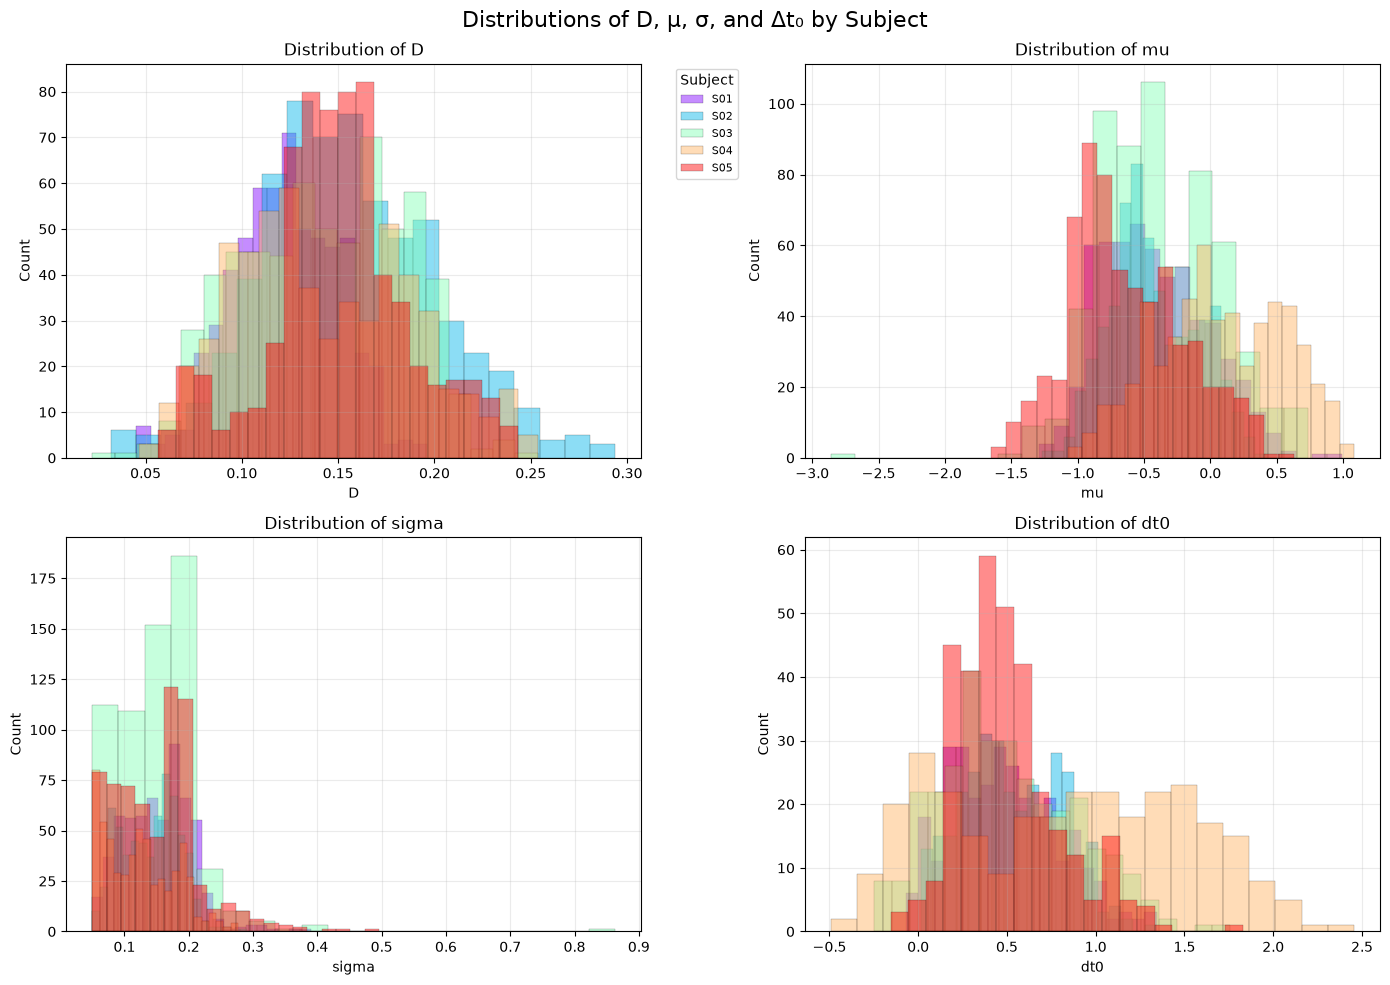

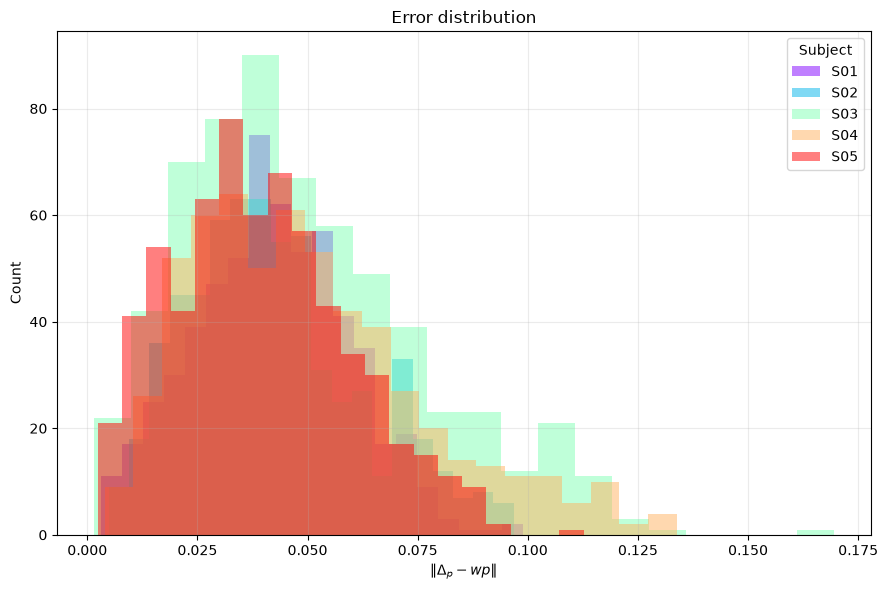

||delta_p - wp|| / ||wp||: median 0.323 | 90th pct 0.634


In [13]:
# Use the processed database and compute D from delta_p when it is not already available.
plot_data = final_database.copy()

# dt0 of the first stroke of a recording is the constant T0_FIRST, not data: it is left out of the plots.
plot_data.loc[plot_data["stroke_number"] == 0, "dt0"] = np.nan

if "D" not in plot_data.columns:
  plot_data["D"] = plot_data["delta_p"].apply(
    lambda v: np.linalg.norm(np.asarray(v, dtype=np.float32))
  )

metrics = ["D", "mu", "sigma", "dt0"]
subjects = sorted(plot_data["subject"].dropna().unique())
colors = plt.cm.rainbow(np.linspace(0, 1, len(subjects)))

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.ravel()

for ax, metric in zip(axes, metrics):
  for subject, color in zip(subjects, colors):
    values = plot_data.loc[
      plot_data["subject"] == subject, metric
    ].dropna()

    ax.hist(
      values,
      bins=20,
      alpha=0.45,
      color=color,
      label=subject,
      edgecolor="black",
      linewidth=0.3,
    )

  ax.set_title(f"Distribution of {metric}")
  ax.set_xlabel(metric)
  ax.set_ylabel("Count")
  ax.grid(alpha=0.25)

axes[0].legend(
  title="Subject",
  bbox_to_anchor=(1.05, 1),
  loc="upper left",
  fontsize=8,
)

fig.suptitle("Distributions of D, μ, σ, and Δt₀ by Subject", fontsize=16)
plt.tight_layout()
plt.show()

plot_data["delta_p_wp_distance"] = plot_data.apply(
  lambda row: np.linalg.norm(
    np.asarray(row["delta_p"], dtype=np.float32)
    - np.asarray(row["wp"], dtype=np.float32)
  ),
  axis=1,
)

plt.figure(figsize=(9, 6))
for subject, color in zip(subjects, colors):
  values = plot_data.loc[
    plot_data["subject"] == subject, "delta_p_wp_distance"
  ].dropna()
  plt.hist(values, bins=20, alpha=0.5, color=color, label=subject)

plt.title("Error distribution")
plt.xlabel(r"$\|\Delta_p - wp\|$")
plt.ylabel("Count")
plt.grid(alpha=0.25)
plt.legend(title="Subject")
plt.tight_layout()
plt.show()


# sanity check of the geometry on the real data: endpoint error relative to the waypoint distance
wp_norm = plot_data["wp"].apply(np.linalg.norm)
rel_error = plot_data["delta_p_wp_distance"] / wp_norm.clip(lower=1e-9)
print(f"||delta_p - wp|| / ||wp||: median {rel_error.median():.3f} | 90th pct {rel_error.quantile(0.9):.3f}")

In [14]:
def prev_vector(series, dim):
    """Previous-stroke column -> list of float32 arrays; strokes without a predecessor get zeros
    (they are masked anyway and flagged by `is_first`)."""
    out = []
    for v in series:
        missing = v is None or (isinstance(v, float) and np.isnan(v))
        out.append(np.zeros(dim, dtype=np.float32) if missing else np.asarray(v, dtype=np.float32).reshape(dim))
    return out


data = final_database.copy()

formatted_data = pd.DataFrame({
    "subject": data["subject"].to_numpy(),
    "task": data["task"].to_numpy(),
    "recording": data["recording"].to_numpy(),
    "stroke_number": data["stroke_number"].to_numpy(),
    "is_first": (data["stroke_number"] == 0).to_numpy().astype(np.float32),

    # conditioning: waypoint vectors in the stroke frame (start = origin)
    "wp": data["wp"],
    "wp_n": data["wp_n"],

    # network targets (delta_p is also a target: the stroke starts at zero and has to reach it)
    "dt0": data["dt0"].to_numpy(),
    "mu": data["mu"].to_numpy(),
    "sigma": data["sigma"].to_numpy(),
    "lambda_e": data["lambda_e"].to_numpy(),
    "u_e": data["u_e"],
    "delta_p": data["delta_p"],

    # start tangent: taken from the data as it is, like every other target
    "lambda_s": data["lambda_s"].to_numpy(),
    "u_s": data["u_s"],

    # previous stroke: same quantities as the outputs, WITHOUT delta_p
    "prev_dt0": prev_vector(data["dt0_previous"], 1),
    "prev_mu": prev_vector(data["mu_previous"], 1),
    "prev_sigma": prev_vector(data["sigma_previous"], 1),
    "prev_lambda_s": prev_vector(data["lambda_s_previous"], 1),
    "prev_u_s": prev_vector(data["u_s_previous"], 3),
    "prev_lambda_e": prev_vector(data["lambda_e_previous"], 1),
    "prev_u_e": prev_vector(data["u_e_previous"], 3),
})

formatted_data.head(10)

,subject,task,recording,stroke_number,is_first,wp,wp_n,dt0,mu,sigma,...,delta_p,lambda_s,u_s,prev_dt0,prev_mu,prev_sigma,prev_lambda_s,prev_u_s,prev_lambda_e,prev_u_e
0,S01,BURSTc_XY,0,0,1.0,"[0.1312, 0.039, 0.0]","[0.0, 0.078, 0.0]",0.200,-0.011085,0.102214,...,"(0.10371880059075336, 0.059843993339055025, -0...",0.052367,"(0.9572918060578811, -0.006244981416900616, 0....",[0.0],[0.0],[0.0],[0.0],"[0.0, 0.0, 0.0]",[0.0],"[0.0, 0.0, 0.0]"
1,S01,BURSTc_XY,0,1,0.0,"[-0.1037188, 0.018156007, 0.021112481]","[-0.1037188, 0.018156007, 0.021112481]",0.782,-0.730318,0.190991,...,"(-0.09716147103264361, 0.02884637293620681, -0...",0.027876,"(-0.2954443212934536, 0.8991320115456447, -0.3...",[0.2],[-0.011085286],[0.10221391],[0.052366834],"[0.9572918, -0.006244981, 0.28905603]",[0.04631386],"[-0.2954443, 0.899132, -0.3229153]"
2,S01,BURSTc_XY,1,0,1.0,"[0.1312, 0.039, 0.0]","[0.0, 0.078, 0.0]",0.200,-0.279243,0.143431,...,"(0.10558556222114279, 0.06166192333448074, -0....",0.056576,"(0.9475777940642627, -0.00034436452862785747, ...",[0.0],[0.0],[0.0],[0.0],"[0.0, 0.0, 0.0]",[0.0],"[0.0, 0.0, 0.0]"
3,S01,BURSTc_XY,1,1,0.0,"[-0.10558556, 0.016338076, 0.0117638325]","[-0.10558556, 0.016338076, 0.0117638325]",0.580,-0.766796,0.211181,...,"(-0.08437866052838575, 0.033816326564298387, -...",0.025388,"(-0.2841902610754754, 0.8990088247219804, -0.3...",[0.2],[-0.27924296],[0.14343129],[0.05657562],"[0.9475778, -0.00034436453, 0.31952497]",[0.046334296],"[-0.28419027, 0.8990088, -0.33319518]"
4,S01,BURSTc_XY,2,0,1.0,"[0.1312, 0.039, 0.0]","[0.0, 0.078, 0.0]",0.200,0.009093,0.117175,...,"(0.09014648924495403, 0.07748150729276071, -0....",0.075618,"(0.9624293357326912, -0.09839493268088058, 0.2...",[0.0],[0.0],[0.0],[0.0],"[0.0, 0.0, 0.0]",[0.0],"[0.0, 0.0, 0.0]"
5,S01,BURSTc_XY,2,1,0.0,"[-0.09014649, 0.0005184927, 0.02410833]","[-0.09014649, 0.0005184927, 0.02410833]",0.864,-0.894429,0.211561,...,"(-0.07863722893820692, 0.02104688130279775, -0...",0.026600,"(-0.5664473896029328, 0.7513963665995308, -0.3...",[0.2],[0.009092815],[0.11717529],[0.07561753],"[0.96242934, -0.09839493, 0.25307748]",[0.048368398],"[-0.5664474, 0.75139636, -0.33843884]"
6,S01,BURSTc_XY,3,0,1.0,"[0.1312, 0.039, 0.0]","[0.0, 0.078, 0.0]",0.200,0.137379,0.087494,...,"(0.10342995150896793, 0.02037846204975123, -0....",0.001000,"(0.9876311171143307, -0.1449824338520533, 0.05...",[0.0],[0.0],[0.0],[0.0],"[0.0, 0.0, 0.0]",[0.0],"[0.0, 0.0, 0.0]"
7,S01,BURSTc_XY,3,1,0.0,"[-0.10342995, 0.05762154, 0.013348131]","[-0.10342995, 0.05762154, 0.013348131]",0.888,-0.596108,0.187996,...,"(-0.08722250359514416, 0.06615814067166575, -0...",0.042826,"(0.3315252126130988, 0.787705988307333, -0.519...",[0.2],[0.13737881],[0.08749408],[0.001],"[0.98763114, -0.14498243, 0.059706535]",[0.047595665],"[0.3315252, 0.787706, -0.51924014]"
8,S01,BURSTc_XY,5,0,1.0,"[0.1312, 0.039, 0.0]","[0.0, 0.078, 0.0]",0.200,-0.520541,0.119402,...,"(0.09177130096489872, 0.0093040202074995, -0.0...",0.027064,"(0.957353410280068, -0.114618843338285, 0.2652...",[0.0],[0.0],[0.0],[0.0],"[0.0, 0.0, 0.0]",[0.0],"[0.0, 0.0, 0.0]"
9,S01,BURSTc_XY,5,1,0.0,"[-0.091771305, 0.06869598, 0.0030959034]","[-0.091771305, 0.06869598, 0.0030959034]",0.298,-0.607996,0.211449,...,"(-0.07839562101335765, 0.07703128328345758, -0...",0.046915,"(0.666957534373123, 0.6125592709342441, -0.424...",[0.2],[-0.5205407],[0.11940243],[0.02706407],"[0.9573534, -0.114618845, 0.26521116]",[0.027086658],"[0.66695756, 0.61255926, -0.42419192]"


## Training

In [15]:
# ---- train / validation split ----
# Dimension that is cut to build the validation set:
#   "sample"  : all subjects and all tasks in both sets; whole trials (recordings) are held out
#   "task"    : all subjects and all samples in both sets; whole tasks are held out
#   "subject" : all tasks and all samples in both sets; whole subjects are held out
SPLIT_BY = "task"
VAL_FRACTION = 0.15
SPLIT_SEED = 0


def split_mask(df, split_by, fraction, seed):
    """Boolean validation mask over the rows of `df`, plus a short description of what was held out."""
    df = df.reset_index(drop=True)
    rng = np.random.default_rng(seed)

    if split_by in ("subject", "task"):
        # Every row of a held-out subject (or task) goes to validation.
        units = np.asarray(df[split_by].unique(), dtype=object)
        rng.shuffle(units)
        held_out = units[: max(1, int(fraction * len(units)))]
        return df[split_by].isin(held_out).to_numpy(), f"held-out {split_by}s: {sorted(held_out)}"

    if split_by == "sample":
        # A sample is one trial (subject, task, recording): its strokes are chained through the previous-stroke
        # input, so they always stay together. Trials are held out inside every (subject, task) pair, which
        # keeps all subjects and all tasks in both sets.
        is_val = np.zeros(len(df), dtype=bool)
        n_held_out, n_single = 0, 0
        for _, group in df.groupby(["subject", "task"]):
            recordings = np.array(sorted(group["recording"].unique()))
            if len(recordings) < 2:
                n_single += 1    # a single trial cannot be in both sets: it stays in training
                continue
            rng.shuffle(recordings)
            n_val = min(len(recordings) - 1, max(1, int(fraction * len(recordings))))
            held_out = recordings[:n_val]
            is_val[group.index[group["recording"].isin(held_out).to_numpy()]] = True
            n_held_out += n_val
        return is_val, f"held-out trials: {n_held_out} | (subject, task) pairs with a single trial: {n_single}"

    raise ValueError("SPLIT_BY must be 'sample', 'task' or 'subject'")


is_val, held_out_description = split_mask(formatted_data, SPLIT_BY, VAL_FRACTION, SPLIT_SEED)
train_df = formatted_data[~is_val].reset_index(drop=True)
val_df = formatted_data[is_val].reset_index(drop=True)
if len(train_df) == 0 or len(val_df) == 0:
    raise ValueError(f"empty training or validation set with SPLIT_BY='{SPLIT_BY}'")

BATCH_RECORDINGS = 8    # whole recordings per batch

train_ds, val_ds = StrokeDataset(train_df), StrokeDataset(val_df)
train_loader = SequenceLoader(train_ds, batch_size=BATCH_RECORDINGS, shuffle=True)
val_loader = SequenceLoader(val_ds, batch_size=BATCH_RECORDINGS, shuffle=False)

# Coverage of each set, to verify which dimensions are shared between training and validation.
print(f"split by {SPLIT_BY} | {held_out_description}")
for name, part in (("train", train_df), ("val", val_df)):
    print(f"{name}: {len(part)} strokes | {part['subject'].nunique()} subjects | {part['task'].nunique()} tasks")


# ---- standardization ----
@torch.no_grad()
def compute_stats(dataset, eps=1e-8):
    """(mean, std) per key, from a StrokeDataset.
    wp, wp_n and delta_p share ONE zero-mean isotropic scale: the stroke origin stays at 0, the three
    vectors stay in the same units and delta_p - wp keeps its geometric meaning (it is just rescaled).
    The unit vectors u_s and u_e (and prev_u_s / prev_u_e, which use the same statistics) also get zero mean
    and one isotropic scale: a rotation of the raw vectors stays a rotation once standardized.
    The statistics of dt0 come from the strokes that are not the first of their recording: the first ones
    carry the constant T0_FIRST."""
    t = dataset.tensors
    stats = {k: (t[k].mean(0), t[k].std(0).clamp_min(eps)) for k in STAT_KEYS}
    later = t["is_first"].reshape(-1) < 0.5
    stats["dt0"] = (t["dt0"][later].mean(0), t["dt0"][later].std(0).clamp_min(eps))
    pooled = torch.cat([t[k].reshape(-1) for k in GEOM_SHARED_KEYS])
    scale = pooled.pow(2).mean().sqrt().clamp_min(eps).item()
    for k in GEOM_SHARED_KEYS:
        d = t[k].size(1)
        stats[k] = (torch.zeros(d), torch.full((d,), scale))
    unit = torch.cat([t[k].reshape(-1) for k in UNIT_VECTOR_KEYS])
    unit_scale = unit.pow(2).mean().sqrt().clamp_min(eps).item()     # 1/sqrt(3) for exact unit vectors
    for k in UNIT_VECTOR_KEYS:
        d = t[k].size(1)
        stats[k] = (torch.zeros(d), torch.full((d,), unit_scale))
    return stats


def _standardize(x, stat, device):
    m, s = stat
    x = x.float().to(device).reshape(x.size(0), -1)
    return (x - m.to(device)) / s.to(device)


def normalize_batch(batch, stats, device):
    """Standardize a batch (or a whole dataset dict) with the training statistics.
    prev_* reuse the statistics of the matching target and are zeroed for first strokes
    (no previous stroke): together with the `is_first` flag this is the start-of-sequence input."""
    is_first = batch["is_first"].float().to(device).reshape(-1, 1)
    out = {"is_first": is_first}
    for k in STAT_KEYS:
        out[k] = _standardize(batch[k], stats[k], device)
    for k in PREV_KEYS:
        out[k] = _standardize(batch[k], stats[k[len("prev_"):]], device) * (1.0 - is_first)
    if "lengths" in batch:
        out["lengths"] = batch["lengths"]
    return out


@torch.no_grad()
def stack_targets(dataset, stats):
    """Standardized targets [N, D] in the order of TARGET_KEYS. The dt0 of the first strokes is a constant,
    not data: it is replaced by the mean of the real delays (0 once standardized)."""
    nb = normalize_batch(dataset.tensors, stats, "cpu")
    targets = torch.cat([nb[k] for k in TARGET_KEYS], dim=-1)
    targets[nb["is_first"].reshape(-1) > 0.5, DT0_INDEX] = 0.0
    return targets


stats = compute_stats(train_ds)

split by task | held-out tasks: ['BURSTc_YZ', 'LETTER_N']
train: 2579 strokes | 5 subjects | 15 tasks
val: 474 strokes | 5 subjects | 2 tasks


In [16]:
from scipy.spatial.transform import Rotation

# ---- online geometric augmentation ----
AUG_PROB = 0.75                # probability that a training stroke is transformed at each step (0 = off)
AUG_REFLECT_PROB = 0.5        # probability of a reflection across a plane of random orientation
AUG_MAX_ANGLE_DEG = 180.0     # random rotation about a random axis: angle in [-max, +max]; >= 180 means uniform on SO(3)
AUG_SEED = 0

# Keys holding 3D vectors in the stroke frame: all of them transform with the same orthogonal matrix.
GEOM_VECTOR_KEYS = ["wp", "wp_n", "u_s", "u_e", "delta_p", "prev_u_s", "prev_u_e"]


def _unit_rows(a):
    """Normalize every row of a 2D array to unit length."""
    return a / np.linalg.norm(a, axis=1, keepdims=True)


def random_orthogonal_batch(n, rng):
    """
    [n, 3, 3] random orthogonal matrices. Each one is an optional reflection across the plane orthogonal to a
    random direction (Householder matrix I - 2 n n^T, applied with probability AUG_REFLECT_PROB), followed by a
    random rotation.
    """
    normals = _unit_rows(rng.normal(size=(n, 3)))
    householder = np.eye(3) - 2.0 * normals[:, :, None] * normals[:, None, :]
    reflect = rng.random(n) < AUG_REFLECT_PROB
    q = np.where(reflect[:, None, None], householder, np.eye(3))

    if AUG_MAX_ANGLE_DEG >= 180.0:
        # Normalized 4D Gaussian = uniformly distributed unit quaternion = uniform rotation on SO(3).
        rotation = Rotation.from_quat(_unit_rows(rng.normal(size=(n, 4))))
    else:
        angle = np.deg2rad(rng.uniform(-AUG_MAX_ANGLE_DEG, AUG_MAX_ANGLE_DEG, size=n))
        rotation = Rotation.from_rotvec(_unit_rows(rng.normal(size=(n, 3))) * angle[:, None])
    return rotation.as_matrix() @ q


class GeometricAugmentation:
    """
    Online augmentation of a raw (not yet standardized) batch {key: tensor [B, d]}.

    A fresh orthogonal matrix is drawn at every call for every recording (for every stroke when the batch has no
    "lengths") and applied to the waypoint vectors, the tangent directions, the displacement and the
    previous-stroke directions of all its strokes together, so a recording stays one consistent sequence. The matrix
    acts around the task origin W0, so lengths, angles and the end-point error ||delta_p - wp|| are unchanged.
    Timing parameters and tangent lengths are invariant and are left as they are. With probability 1 - prob a
    stroke keeps the identity, so the original orientation distribution is still seen during training.
    """

    def __init__(self, prob=AUG_PROB, seed=AUG_SEED):
        self.prob = float(prob)
        self.rng = np.random.default_rng(seed)

    def __call__(self, raw):
        if self.prob <= 0:
            return raw
        lengths = raw.get("lengths")
        n = len(lengths) if lengths is not None else raw["wp"].size(0)
        q = random_orthogonal_batch(n, self.rng)
        q[self.rng.random(n) >= self.prob] = np.eye(3)
        q = torch.from_numpy(q).float()
        if lengths is not None:
            q = q.repeat_interleave(torch.as_tensor(lengths), dim=0)

        out = dict(raw)
        for key in GEOM_VECTOR_KEYS:
            out[key] = torch.einsum("nij,nj->ni", q, raw[key].float())
        return out


# ---- input noise ----
NOISE_PREV = 0.005    # std of the noise on the previous-stroke input (standardized units)
NOISE_WP = 0.01      # std of the noise on the waypoint vectors (standardized units)


def add_input_noise(batch, noise_prev=NOISE_PREV, noise_wp=NOISE_WP):
    """Gaussian noise on the conditioning inputs of a normalized batch; targets and the first-stroke flag stay clean."""
    if noise_prev <= 0 and noise_wp <= 0:
        return batch
    noisy = dict(batch)
    if noise_wp > 0:
        for key in ("wp", "wp_n"):
            noisy[key] = batch[key] + noise_wp * torch.randn_like(batch[key])
    if noise_prev > 0:
        not_first = 1.0 - batch["is_first"]    # first strokes keep the exact start-of-sequence input
        for key in PREV_KEYS:
            noisy[key] = batch[key] + noise_prev * torch.randn_like(batch[key]) * not_first
    return noisy

### Training loop

Adam on the mixture NLL. The best model is chosen on the **validation mixture NLL**; the history also records, for every epoch, the mean and the largest gradient norm before clipping.

In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
INPUT_DIM = 2 * train_ds.tensors["wp"].size(1) + 1                     # wp, wp_n, is_first
OUTPUT_DIM = sum(train_ds.tensors[k].size(1) for k in TARGET_KEYS)     # dt0, mu, sigma, lambda_e, u_e, delta_p
RECUR_DIM = sum(train_ds.tensors[k].size(1) for k in PREV_KEYS)        # same without delta_p
print(f"input {INPUT_DIM} | output {OUTPUT_DIM} | previous-stroke {RECUR_DIM}")
EMBEDDING_DIM = 16
MIXTURE_COMPONENTS = 1
LSTM_DIM = 64
LSTM_COUNT = 1
MDN_HIDDEN_DIM = 96
COVARIANCE = "full"      # "full": lower Cholesky factor | "diagonal": independent dimensions within a component
STATEFUL = True          # LSTM state carried along the strokes of a recording

input 7 | output 14 | previous-stroke 11


In [18]:
import random


def set_seed(seed: int):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)



def build_model(mixture_components=MIXTURE_COMPONENTS, lstm_dim=LSTM_DIM, lstm_count=LSTM_COUNT,
                mdn_hidden_dim=MDN_HIDDEN_DIM, covariance=COVARIANCE, stateful=STATEFUL):
    """Fresh, initialised model; unspecified architecture values fall back to the notebook defaults."""
    model = GenerativeModel(
        input_dim=INPUT_DIM,
        LSTM_dim=lstm_dim, LSTM_count=lstm_count,
        output_dim=OUTPUT_DIM, mixture_components=mixture_components,
        recur_dim=RECUR_DIM, mdn_hidden_dim=mdn_hidden_dim,
        covariance=covariance, stateful=STATEFUL if stateful is None else stateful,
    ).to(device)
    model.set_weights(stack_targets(train_ds, stats).to(device))
    return model

@torch.no_grad()
def evaluate_nll(model, loader, stats):
    """Mean mixture NLL on a loader: the model-selection metric."""
    model.eval()
    total, count = 0.0, 0
    for raw in loader:
        batch = normalize_batch(raw, stats, device)
        x, prev, target = model_io(batch, device)
        means, scale_tril, logits = model(x, prev_output=prev, lengths=batch.get("lengths"))
        size = x.size(0)
        total += mixture_nll(means, scale_tril, logits, target, batch["is_first"]).item() * size
        count += size
    return total / count


def save_checkpoint(path, model, stats, epoch, val_nll):
    torch.save({
        "model_state": model.state_dict(),
        "stats": stats,
        "config": model.arch,
        "target_keys": list(TARGET_KEYS),
        "prev_keys": list(PREV_KEYS),
        "loss": "nll",
        "epoch": epoch,
        "val_nll": val_nll,
    }, path)


def load_checkpoint(path):
    """-> (model in eval mode, stats, checkpoint dict)."""
    ckpt = torch.load(path, map_location=device, weights_only=False)
    if ckpt["target_keys"] != list(TARGET_KEYS) or ckpt["prev_keys"] != list(PREV_KEYS):
        raise ValueError("the checkpoint was trained with different TARGET_KEYS / PREV_KEYS")
    model = GenerativeModel(**ckpt["config"]).to(device)
    model.load_state_dict(ckpt["model_state"])
    model.eval()
    return model, ckpt["stats"], ckpt


def train_model(model, train_loader, val_loader, stats, epochs=100, lr=1e-3, weight_decay=0.0, grad_clip=1.0,
                ckpt_path="best_stroke_model.pt", patience=None, verbose=True, noise_prev=0.0, noise_wp=0.0,
                augmentation=None):
    """
    Adam training on the mixture NLL; the checkpoint with the lowest validation NLL is saved and restored at the
    end. The history also holds the mean and the largest gradient norm of every epoch, measured before clipping.
    """
    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    best_val, best_epoch, history = float("inf"), 0, []

    for epoch in range(1, epochs + 1):
        model.train()
        total, count, grad_norms = 0.0, 0, []
        for raw in train_loader:
            if augmentation is not None:
                raw = augmentation(raw)
            batch = add_input_noise(normalize_batch(raw, stats, device), noise_prev, noise_wp)
            nll = mdn_nll_loss(model, batch, device)
            optimizer.zero_grad(set_to_none=True)
            nll.backward()
            max_norm = grad_clip if grad_clip is not None else float("inf")
            grad_norms.append(torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm).item())
            optimizer.step()
            size = batch["wp"].size(0)
            total += nll.item() * size
            count += size

        train_nll = total / count
        val_nll = evaluate_nll(model, val_loader, stats)
        history.append({"epoch": epoch, "train_nll": train_nll, "val_nll": val_nll,
                        "grad_norm_mean": float(np.mean(grad_norms)), "grad_norm_max": float(np.max(grad_norms))})
        if not (np.isfinite(train_nll) and np.isfinite(val_nll)):
            print(f"epoch {epoch}: non-finite loss, stopping")
            break

        improved = val_nll < best_val
        if improved:
            best_val, best_epoch = val_nll, epoch
            save_checkpoint(ckpt_path, model, stats, epoch, val_nll)
        if verbose:
            print(f"epoch {epoch:3d} | train NLL {train_nll:9.4f} | val NLL {val_nll:9.4f}" + ("  *" if improved else ""))
        if patience is not None and epoch - best_epoch >= patience:
            print(f"no improvement for {patience} epochs: early stop")
            break

    if best_epoch == 0:
        raise RuntimeError("no finite validation loss: nothing was saved")
    model.load_state_dict(torch.load(ckpt_path, map_location=device, weights_only=False)["model_state"])
    print(f"best epoch {best_epoch} | val NLL {best_val:.4f} | saved to {ckpt_path}")
    return history


def plot_history(history, title=None):
    epochs = [h["epoch"] for h in history]
    best = min(history, key=lambda h: h["val_nll"])
    fig, ax = plt.subplots(figsize=(8, 4))
    ax.plot(epochs, [h["train_nll"] for h in history], label="train NLL")
    ax.plot(epochs, [h["val_nll"] for h in history], label="validation NLL")
    ax.axvline(best["epoch"], color="gray", linestyle=":", label=f"best epoch ({best['epoch']})")
    ax.set_xlabel("epoch")
    ax.set_ylabel("mixture NLL")
    ax.set_title(title or "Training history")
    ax.grid(alpha=0.3)
    ax.legend()
    plt.tight_layout()
    plt.show()

### Checks on the onset delay

The network must learn `dt0` only from strokes that have a predecessor: the data are checked first, then the gradients of a batch of first strokes and of a batch of later strokes.

In [19]:
# Data: the first stroke of every recording carries the constant; every later dt0 is the delay from its predecessor,
# and the previous-stroke input of a stroke is exactly the dt0 of the stroke before it.
first = formatted_data["stroke_number"] == 0
assert (formatted_data.loc[first, "dt0"] == T0_FIRST).all(), "first strokes must carry T0_FIRST"
assert np.array_equal(first.to_numpy().astype(np.float32), formatted_data["is_first"].to_numpy()), "is_first mismatch"
for _, group in formatted_data.sort_values("stroke_number").groupby(["subject", "task", "recording"]):
    assert (np.diff(group["stroke_number"].to_numpy()) == 1).all(), "non-consecutive strokes in a recording"
    dt0 = group["dt0"].to_numpy(dtype=float)
    prev_dt0 = np.concatenate(group["prev_dt0"].to_list()).astype(float)
    assert np.allclose(prev_dt0[1:], dt0[:-1]), "prev_dt0 is not the dt0 of the previous stroke"


# Gradient: strokes that are the first of a recording must not move the mean or the scale of dt0,
# while the other strokes must.
def dt0_gradients(model, rows):
    """Gradients of the mixture NLL of the strokes `rows` on the weights that produce the mean and the scale of dt0."""
    batch = normalize_batch(train_ds[rows.tolist()], stats, device)
    model.zero_grad()
    mdn_nll_loss(model, batch, device).backward()
    mdn = model.mdn
    K, D, m = mdn.num_components, mdn.output_dim, mdn.num_scale
    # (dt0, dt0) entry: row-major lower triangle for full covariances, plain index for diagonal ones
    scale_index = DT0_INDEX * (DT0_INDEX + 3) // 2 if mdn.covariance == "full" else DT0_INDEX
    return {
        "mean": mdn.means_layer.weight.grad.reshape(K, D, -1)[:, DT0_INDEX],
        "scale": mdn.scale_layer.weight.grad.reshape(K, m, -1)[:, scale_index],
    }


is_first_rows = train_ds.tensors["is_first"].numpy().reshape(-1) > 0.5
check_model = build_model()
from_first = dt0_gradients(check_model, np.flatnonzero(is_first_rows)[:32])
from_later = dt0_gradients(check_model, np.flatnonzero(~is_first_rows)[:32])
assert all(torch.count_nonzero(g) == 0 for g in from_first.values()), "first strokes move dt0"
assert all(torch.count_nonzero(g) > 0 for g in from_later.values()), "later strokes do not move dt0"
print("dt0 checks passed")


dt0 checks passed


In [ ]:
PATIENCE_EPOCHS = 100
EPOCHS = 1500
LR = 1e-4
CKPT_PATH = "best_stroke_model_nll.pt"

#set_seed(0)
model = build_model()
history = train_model(model, train_loader, val_loader, stats, patience=PATIENCE_EPOCHS, epochs=EPOCHS, lr=LR,
                      ckpt_path=CKPT_PATH, noise_prev=NOISE_PREV, noise_wp=NOISE_WP,
                      augmentation=GeometricAugmentation(AUG_PROB, AUG_SEED))
plot_history(history, title="Training history (NLL)")

epoch   1 | train NLL   41.9112 | val NLL   31.6855  *
epoch   2 | train NLL   24.6272 | val NLL   19.4985  *
epoch   3 | train NLL   17.7322 | val NLL   17.5833  *
epoch   4 | train NLL   15.4997 | val NLL   16.3895  *
epoch   5 | train NLL   14.4882 | val NLL   14.9353  *
epoch   6 | train NLL   13.5817 | val NLL   13.9221  *
epoch   7 | train NLL   12.9296 | val NLL   12.9970  *
epoch   8 | train NLL   12.2920 | val NLL   12.5893  *
epoch   9 | train NLL   11.8394 | val NLL   12.0283  *
epoch  10 | train NLL   11.4649 | val NLL   12.0160  *
epoch  11 | train NLL   11.1396 | val NLL   11.2708  *
epoch  12 | train NLL   10.8204 | val NLL   10.9362  *
epoch  13 | train NLL   10.6964 | val NLL   10.9611
epoch  14 | train NLL   10.5176 | val NLL   10.9361  *
epoch  15 | train NLL   10.4198 | val NLL   10.6255  *
epoch  16 | train NLL   10.2110 | val NLL   10.3001  *
epoch  17 | train NLL   10.0607 | val NLL   10.1379  *
epoch  18 | train NLL   10.0083 | val NLL    9.8899  *
epoch  19 | t

In [ ]:
import itertools
import os
import time

import pandas as pd

# ---- search settings ----
# Every key is one hyperparameter; the search draws combinations of these values.
SEARCH_SPACE = {
    "mixture_components": [1, 2, 4, 8],
    "lstm_dim": [32, 64, 128],
    "lstm_count": [1, 2],
    "embedding_dim": [8, 16],
    "lr": [3e-4, 1e-3],
    "weight_decay": [0.0, 1e-4],
    "noise_prev": [0.0, 0.15],
    "noise_wp": [0.0, 0.05],
    "aug_prob": [0.0, 0.5],
}
SEARCH_MODE = "random"      # "grid": every combination | "random": N_TRIALS distinct combinations
N_TRIALS = 30
SEEDS = [23, 733, 32647]                 # seeds per configuration; use several to separate real differences from seed noise
SEARCH_EPOCHS = 5000         # budget of a single trial (shorter than the final training)
SEARCH_PATIENCE = 100
RESULTS_PATH = "search_results.csv"
CKPT_DIR = "search_ckpts"

# Architecture keys passed to build_model. "mdn_hidden_dim", "covariance" and "stateful" can be added to
# SEARCH_SPACE; when absent the notebook defaults are used. A different set of keys needs a new RESULTS_PATH,
# because the columns of the log change.
ARCH_KEYS = ["mixture_components", "lstm_dim", "lstm_count", "embedding_dim", "mdn_hidden_dim", "covariance", "stateful"]


def sample_configs(space, mode, n_trials, seed=0):
    """Configurations to evaluate: the full grid, or n_trials distinct random combinations of it."""
    keys = list(space)
    grid = [dict(zip(keys, values)) for values in itertools.product(*space.values())]
    if mode == "grid":
        return grid
    picks = np.random.default_rng(seed).choice(len(grid), size=min(n_trials, len(grid)), replace=False)
    return [grid[i] for i in picks]


def run_trial(config, seed, trial_id):
    """Train one configuration from scratch and return its configuration plus validation-NLL diagnostics."""
    set_seed(seed)
    model = build_model(**{k: config[k] for k in ARCH_KEYS if k in config})
    ckpt_path = os.path.join(CKPT_DIR, f"trial_{trial_id}_seed_{seed}.pt")
    augmentation = (
        GeometricAugmentation(config["aug_prob"], AUG_SEED + seed) if config["aug_prob"] > 0 else None
    )

    start = time.time()
    history = train_model(
        model, train_loader, val_loader, stats, epochs=SEARCH_EPOCHS,
        patience=SEARCH_PATIENCE, lr=config["lr"], weight_decay=config["weight_decay"],
        ckpt_path=ckpt_path, verbose=False, noise_prev=config["noise_prev"],
        noise_wp=config["noise_wp"], augmentation=augmentation,
    )
    best = min(history, key=lambda h: h["val_nll"])
    return {
        **config,
        "seed": seed,
        "best_val_nll": best["val_nll"],
        "train_nll_at_best": best["train_nll"],
        "best_epoch": best["epoch"],
        "epochs_run": len(history),
        "n_params": sum(p.numel() for p in model.parameters()),
        "seconds": round(time.time() - start, 1),
        "ckpt_path": ckpt_path,
    }


def run_search(configs, seeds):
    """Run every (configuration, seed) pair; each result is appended to RESULTS_PATH as soon as it is ready."""
    os.makedirs(CKPT_DIR, exist_ok=True)
    rows = []
    for trial_id, config in enumerate(configs):
        for seed in seeds:
            try:
                row = run_trial(config, seed, trial_id)
            except (RuntimeError, ValueError) as error:    # validation loss never finite, or a degenerate covariance
                row = {**config, "seed": seed, "best_val_nll": float("nan"), "train_nll_at_best": float("nan"),
                       "best_epoch": float("nan"), "epochs_run": float("nan"), "n_params": float("nan"),
                       "seconds": float("nan"), "ckpt_path": ""}
                print(f"trial {trial_id + 1} seed {seed} failed: {str(error)[:200]}")
            row["trial"] = trial_id
            rows.append(row)
            pd.DataFrame([row]).to_csv(RESULTS_PATH, mode="a", header=not os.path.exists(RESULTS_PATH), index=False)
            print(f"trial {trial_id + 1}/{len(configs)} seed {seed} | val NLL {row['best_val_nll']:.4f} | {config}")
    return pd.DataFrame(rows)


def summarize(results):
    """Configurations ranked by mean best validation NLL over seeds (std is meaningful with several seeds)."""
    keys = list(SEARCH_SPACE)
    summary = results.groupby(keys)["best_val_nll"].agg(["mean", "std", "min", "count"]).reset_index()
    params = results.groupby(keys)["n_params"].first().reset_index()
    return summary.merge(params, on=keys).sort_values("mean").reset_index(drop=True)


# ---- usage ----
# if os.path.exists(RESULTS_PATH): os.remove(RESULTS_PATH)     # start a new search from an empty log
# configs = sample_configs(SEARCH_SPACE, SEARCH_MODE, N_TRIALS)
# results = run_search(configs, SEEDS)
# print(summarize(results).head(10).to_string(index=False))
#
# best = results.loc[results["best_val_nll"].idxmin()]
# model, stats, ckpt = load_checkpoint(best["ckpt_path"])

In [ ]:
configs = sample_configs(SEARCH_SPACE, SEARCH_MODE, N_TRIALS)
results = run_search(configs, SEEDS)
print(summarize(results).head(10).to_string(index=False))

In [ ]:
import matplotlib.pyplot as plt


def per_config(results):
    """One row per configuration: mean, standard error and single-seed values of the best validation NLL."""
    keys = list(SEARCH_SPACE)
    rows = []
    for values, group in results.dropna(subset=["best_val_nll"]).groupby(keys):
        v = group["best_val_nll"].to_numpy()
        row = dict(zip(keys, values))
        row.update(
            mean=v.mean(),
            sem=v.std(ddof=1) / np.sqrt(len(v)) if len(v) > 1 else 0.0,
            values=v,
            n_params=int(group["n_params"].iloc[0]),
            train_at_best=group["train_nll_at_best"].mean(),
        )
        rows.append(row)
    return pd.DataFrame(rows).sort_values("mean").reset_index(drop=True)


def config_label(row):
    """Compact one-line description of a configuration."""
    return (
        f"K={int(row['mixture_components'])} | H={int(row['lstm_dim'])}x{int(row['lstm_count'])} | "
        f"E={int(row['embedding_dim'])} | lr={row['lr']:g} | wd={row['weight_decay']:g} | "
        f"noise p={row['noise_prev']:g} w={row['noise_wp']:g} | aug={row['aug_prob']:g}"
    )


def plot_ranking(configs, top=15):
    """Best configurations, with the single seeds and the mean +- s.e.m.; the band marks the best +- s.e.m."""
    shown = configs.head(top).iloc[::-1]    # best configuration on top
    best = configs.iloc[0]
    y = np.arange(len(shown))

    fig, ax = plt.subplots(figsize=(11, 0.4 * len(shown) + 1.6))
    ax.axvspan(best["mean"] - best["sem"], best["mean"] + best["sem"], color="tab:green", alpha=0.15,
               label="best configuration, mean +- s.e.m.")
    ax.errorbar(shown["mean"], y, xerr=shown["sem"], fmt="o", color="tab:blue", capsize=3,
                label="mean +- s.e.m. over seeds")
    for yi, values in zip(y, shown["values"]):
        ax.scatter(values, np.full(len(values), yi), s=14, color="gray", alpha=0.7, zorder=3)
    ax.scatter([], [], s=14, color="gray", label="single seed")
    ax.set_yticks(y)
    ax.set_yticklabels([config_label(r) for _, r in shown.iterrows()], fontsize=8)
    ax.set_xlabel("best validation NLL")
    ax.set_title("Configurations ranked by validation NLL")
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)
    plt.tight_layout()
    plt.show()


def plot_hyperparameter_effects(configs):
    """For each hyperparameter, validation NLL of every configuration grouped by value (black line = median)."""
    names = list(SEARCH_SPACE)
    n_cols = 3
    n_rows = int(np.ceil(len(names) / n_cols))
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(4.2 * n_cols, 3.2 * n_rows), sharey=True)
    rng = np.random.default_rng(0)

    for ax, name in zip(axes.ravel(), names):
        levels = sorted(configs[name].unique())
        for i, level in enumerate(levels):
            values = configs.loc[configs[name] == level, "mean"].to_numpy()
            ax.scatter(i + rng.uniform(-0.12, 0.12, len(values)), values, s=18, alpha=0.7)
            ax.hlines(np.median(values), i - 0.3, i + 0.3, color="black", linewidth=2)
        counts = [int((configs[name] == level).sum()) for level in levels]
        ax.set_xticks(range(len(levels)))
        ax.set_xticklabels([f"{level:g}\n(n={n})" for level, n in zip(levels, counts)], fontsize=8)
        ax.set_title(name)
        ax.grid(alpha=0.3)
    for ax in axes.ravel()[len(names):]:
        ax.axis("off")
    for ax in axes[:, 0]:
        ax.set_ylabel("validation NLL")
    fig.suptitle("Effect of each hyperparameter (other hyperparameters vary freely)")
    plt.tight_layout()
    plt.show()


def plot_capacity_and_gap(configs):
    """Left: validation NLL against the number of parameters. Right: training against validation NLL."""
    components = sorted(configs["mixture_components"].unique())
    colors = plt.cm.viridis(np.linspace(0, 1, len(components)))
    fig, (ax_cap, ax_gap) = plt.subplots(1, 2, figsize=(12, 4.5))

    for k, color in zip(components, colors):
        sub = configs[configs["mixture_components"] == k]
        ax_cap.errorbar(sub["n_params"], sub["mean"], yerr=sub["sem"], fmt="o", color=color, capsize=2,
                        label=f"K={k}")
        ax_gap.scatter(sub["train_at_best"], sub["mean"], color=color, label=f"K={k}")

    ax_cap.set_xscale("log")
    ax_cap.set_xlabel("number of parameters")
    ax_cap.set_ylabel("validation NLL")
    ax_cap.set_title("Capacity")
    ax_cap.grid(alpha=0.3)
    ax_cap.legend(title="mixture components")

    low = min(configs["train_at_best"].min(), configs["mean"].min())
    high = max(configs["train_at_best"].max(), configs["mean"].max())
    ax_gap.plot([low, high], [low, high], "k--", linewidth=1)    # equal training and validation NLL
    ax_gap.set_xlabel("training NLL at the best epoch (on augmented, noisy inputs)")
    ax_gap.set_ylabel("validation NLL")
    ax_gap.set_title("Training vs validation")
    ax_gap.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()


# ---- usage ----
RESULTS_PATH = "/home/ddacunto/Desktop/ros2_ws/src/master_thesis_data_analysis/data/framework/search_results.csv"
results = pd.read_csv(RESULTS_PATH)
configs = per_config(results)
plot_ranking(configs)
plot_hyperparameter_effects(configs)
plot_capacity_and_gap(configs)

In [ ]:
from scipy import stats as sps


def holm_adjust(p_values):
    """Holm step-down adjustment of a list of p-values (controls the family-wise error rate)."""
    p = np.asarray(p_values, dtype=float)
    adjusted = np.empty_like(p)
    running = 0.0
    for rank, idx in enumerate(np.argsort(p)):
        running = max(running, (len(p) - rank) * p[idx])
        adjusted[idx] = min(1.0, running)
    return adjusted


def compare_to_best(configs, top=10):
    """
    Welch t-test between the best configuration and each of the next `top` ones, with the seeds as replicates.
    It tests only the variability due to initialization and batch order, on this fixed validation set.
    """
    best = configs.iloc[0]
    rows = []
    for _, other in configs.iloc[1:top + 1].iterrows():
        t, p = sps.ttest_ind(other["values"], best["values"], equal_var=False)
        rows.append({
            "configuration": config_label(other),
            "mean_diff": other["mean"] - best["mean"],
            "t": t,
            "p": p,
        })
    table = pd.DataFrame(rows)
    table["p_holm"] = holm_adjust(table["p"])
    return table


def test_hyperparameters(configs):
    """
    Does a hyperparameter shift the validation NLL across the sampled configurations?
    Mann-Whitney U for two levels, Kruskal-Wallis for more; the other hyperparameters vary freely and act as noise.
    """
    rows = []
    for name in SEARCH_SPACE:
        levels = sorted(configs[name].unique())
        groups = [configs.loc[configs[name] == level, "mean"].to_numpy() for level in levels]
        if len(groups) < 2 or min(len(g) for g in groups) < 2:
            continue
        if len(groups) == 2:
            test, p = "Mann-Whitney U", sps.mannwhitneyu(*groups, alternative="two-sided").pvalue
        else:
            test, p = "Kruskal-Wallis", sps.kruskal(*groups).pvalue
        rows.append({
            "hyperparameter": name,
            "test": test,
            "median NLL by level": ", ".join(f"{l:g}: {np.median(g):.2f}" for l, g in zip(levels, groups)),
            "p": p,
        })
    table = pd.DataFrame(rows)
    table["p_holm"] = holm_adjust(table["p"])
    return table.sort_values("p").reset_index(drop=True)


def pooled_seed_std(configs):
    """Standard deviation of the validation NLL across seeds, pooled over the configurations with several seeds."""
    variances = [v.var(ddof=1) for v in configs["values"] if len(v) > 1]
    return float(np.sqrt(np.mean(variances)))


def seeds_needed(sigma, delta, alpha=0.05, power=0.8):
    """Seeds per configuration needed to detect a mean difference `delta` given a seed standard deviation `sigma`."""
    z = sps.norm.ppf(1 - alpha / 2) + sps.norm.ppf(power)
    return int(np.ceil(2 * (z * sigma / delta) ** 2))


# ---- usage ----
print(compare_to_best(configs).to_string(index=False))
print(test_hyperparameters(configs).to_string(index=False))
print(seeds_needed(pooled_seed_std(configs), delta=0.3))

## Generation

Given a task and a seed the stroke network is sampled **autoregressively**, one stroke per waypoint (stroke k aims at W[k+1]). Each stroke is conditioned on its waypoint vectors, expressed in the frame whose origin is where the previous generated stroke ended, and on the previous generated stroke. Then:

* `D` of every stroke is the arc length of its Bezier segment (this is exactly what the dataset enforces: `Ds = D`);
* the total speed is the sum of the lognormals; its local minima between consecutive strokes are the segment boundaries;
* the path is generated with the Bezier primitives of `BezierOptimization`, placing the samples at the arc-length fraction given by the normalized cumulative of the total speed (`output_sigma` logic);
* the onset of the first stroke is the constant `T0_FIRST`, and every later onset is the previous one plus the sampled delay `dt0`.

In [ ]:
LAMBDA_MIN = 1e-3            # same lower bound used when the dataset was built
SIGMA_MIN = 1e-3
Z_TAIL = 2.5758293035489004  # standard-normal quantile of 99.5 %
MAX_SAMPLES = 2_000_000


def _unit(v):
    v = np.asarray(v, dtype=float)
    return v / max(np.linalg.norm(v), 1e-8)


def sample_stroke(model, stats, task, k, start, prev, state=None, deterministic=False):
    """
    One autoregressive step. `start` conditions wp / wp_n (as in training); `prev` is the previous stroke or None;
    `state` is the LSTM state after the previous stroke (None at the start). Returns (stroke, new state).
    """
    wp, wp_n = stroke_deltas(task, k, start)
    is_first = torch.full((1, 1), 1.0 if prev is None else 0.0, device=device)
    x = torch.cat([
        _standardize(torch.from_numpy(wp)[None], stats["wp"], device),
        _standardize(torch.from_numpy(wp_n)[None], stats["wp_n"], device),
        is_first,
    ], dim=-1)

    if prev is None:
        prev_vec = torch.zeros(1, RECUR_DIM, device=device)      # start-of-sequence input, as in training
    else:
        prev_vec = torch.cat([
            _standardize(
                torch.as_tensor(np.asarray(prev[key[len("prev_"):]], dtype=np.float32)).reshape(1, -1),
                stats[key[len("prev_"):]], device)
            for key in PREV_KEYS
        ], dim=-1)

    out, state = model.sample(x, prev_output=prev_vec, state=state, deterministic=deterministic)
    out = out.cpu()                                               # [1, OUTPUT_DIM], standardized

    params, i = {}, 0
    for key in TARGET_KEYS:
        mean, std = stats[key][0].cpu(), stats[key][1].cpu()
        d = mean.numel()
        params[key] = (out[:, i:i + d] * std + mean).numpy()[0]
        i += d

    # the network is Gaussian on R^n: project the samples back on the valid set;
    # the delay of the first stroke is the constant T0_FIRST (that output is not trained)
    return {
        "dt0": T0_FIRST if prev is None else float(params["dt0"][0]),
        "mu": float(params["mu"][0]),
        "sigma": max(float(params["sigma"][0]), SIGMA_MIN),
        "lambda_s": max(float(params["lambda_s"][0]), LAMBDA_MIN),
        "u_s": _unit(params["u_s"]),
        "lambda_e": max(float(params["lambda_e"][0]), LAMBDA_MIN),
        "u_e": _unit(params["u_e"]),
        "delta_p": params["delta_p"].astype(np.float64),
    }, state


@torch.no_grad()
def generate_task(model, stats, task, seed, n_strokes=None, wp_reference=WP_REFERENCE, deterministic=False):
    """All the stroke parameters needed to execute `task`, for a given seed."""
    if task not in WAYPOINTS_BY_TASK:
        raise KeyError(f"unknown task '{task}'. Available: {sorted(WAYPOINTS_BY_TASK)}")
    waypoints = WAYPOINTS_BY_TASK[task]
    n_strokes = len(waypoints) - 1 if n_strokes is None else int(n_strokes)

    set_seed(seed)
    model.eval()
    strokes, prev, state = [], None, None
    chain = waypoints[0].astype(np.float64)          # where the previous stroke ended
    onset = 0.0                                      # absolute onset of the current stroke: cumulative sum of dt0
    for k in range(n_strokes):
        # conditioning frame: same convention used to build the dataset
        start = chain if wp_reference == "actual" else waypoints[min(k, len(waypoints) - 1)].astype(np.float64)
        stroke, state = sample_stroke(model, stats, task, k, start, prev, state=state, deterministic=deterministic)
        onset += stroke["dt0"]
        stroke["t0"] = onset
        stroke["stroke_number"] = k
        stroke["p0"] = chain.copy()
        stroke["p3"] = chain + stroke["delta_p"]
        chain = stroke["p3"]
        strokes.append(stroke)
        prev = stroke
    return strokes


def lognormal_cdf(t, t0, mu, sigma):
    """Fraction of its total length covered by a lognormal stroke at the times `t`."""
    t = np.asarray(t, dtype=float)
    phi = np.zeros_like(t)
    after = t > t0
    phi[after] = 0.5 * (1.0 + erf((np.log(t[after] - t0) - mu) / (sigma * np.sqrt(2.0))))
    return phi


def build_task_curve(strokes, dt=0.005):
    """
    Speed profiles and Bezier path of a generated stroke sequence (sampled every `dt` seconds).
    Segment k of the Bezier chain has length D_k and the chain is traversed with the distance
    travelled by the model, S(t) = sum_k D_k Phi_k(t): the path speed is the sum of the lognormals.
    """
    for s in strokes:
        s["D"] = BezierOptimization._arc_length(s["lambda_s"], s["lambda_e"], s["p0"], s["p3"], s["u_s"], s["u_e"])

    # time window: 0.5 % quantile of the earliest stroke -> 99.5 % quantile of the latest one
    def edge(s, z):
        return s["t0"] + np.exp(s["mu"] + z * s["sigma"])

    t_start = min(edge(s, -Z_TAIL) for s in strokes)
    t_end = max(edge(s, Z_TAIL) for s in strokes)
    if not (np.isfinite(t_start) and np.isfinite(t_end)) or (t_end - t_start) / dt > MAX_SAMPLES:
        raise ValueError("the generated timing is degenerate: try another seed")
    t = np.arange(t_start, t_end + dt, dt)

    v_all = np.vstack([Stroke.lognormal_speed(t, s["D"], s["t0"], s["mu"], s["sigma"]) for s in strokes])
    v_tot = v_all.sum(axis=0)
    travelled = sum(s["D"] * lognormal_cdf(t, s["t0"], s["mu"], s["sigma"]) for s in strokes)

    # segment reached at each time and arc-length fraction inside that segment
    starts = np.concatenate([[0.0], np.cumsum([s["D"] for s in strokes])])
    distance = np.clip(travelled, 0.0, starts[-1])
    segment = np.clip(np.searchsorted(starts, distance, side="right") - 1, 0, len(strokes) - 1)

    points = np.empty((t.size, 3))
    for k, s in enumerate(strokes):
        mask = segment == k
        if not np.any(mask):
            continue
        fraction = (distance[mask] - starts[k]) / s["D"]
        param = BezierOptimization._arclength_parameters(fraction, s["lambda_s"], s["lambda_e"], s["p0"], s["p3"], s["u_s"], s["u_e"])
        points[mask] = BezierOptimization._bezier(param, s["lambda_s"], s["lambda_e"], s["p0"], s["p3"], s["u_s"], s["u_e"])

    # samples at which the movement crosses each junction between consecutive segments
    junctions = np.minimum(np.searchsorted(travelled, starts[1:-1]), t.size - 1)

    # local extrema of the total speed; first and last samples count as minima
    minima = np.unique(np.r_[0, find_peaks(-v_tot)[0], t.size - 1])
    maxima = find_peaks(v_tot)[0]

    return {
        "strokes": strokes, "t": t, "v_all": v_all, "v_tot": v_tot, "points": points,
        "travelled": travelled, "junctions": junctions, "minima": minima, "maxima": maxima,
        "path_speed": np.linalg.norm(np.gradient(points, t, axis=0), axis=1),
    }

In [ ]:
def plot_speed(res, title="", overlay_path_speed=True):
    """Superposition of the lognormal speed profiles."""
    t, strokes = res["t"], res["strokes"]
    n = len(strokes)
    colors = plt.cm.coolwarm_r(np.linspace(0, 1, n))

    fig, ax = plt.subplots(figsize=(12, 5))
    for k in range(n):
        ax.plot(t, res["v_all"][k], color=colors[k], linewidth=1.3, label=f"stroke {k}" if n <= 12 else None)
        ax.fill_between(t, res["v_all"][k], color=colors[k], alpha=0.12)
    ax.plot(t, res["v_tot"], color="black", linewidth=2, label="sum of lognormals")
    if overlay_path_speed:
        ax.plot(t, res["path_speed"], color="black", linestyle="--", linewidth=1, label="speed of the Bezier path")
    ax.scatter(t[res["minima"]], res["v_tot"][res["minima"]], color="tab:blue", s=45, zorder=4, label="speed minima")
    ax.scatter(t[res["maxima"]], res["v_tot"][res["maxima"]], color="tab:orange", s=45, zorder=4, label="speed maxima")
    ax.set_xlabel("time [s]")
    ax.set_ylabel("speed [m/s]")
    ax.set_title(title or "Generated lognormal speed profiles")
    ax.grid(True)
    ax.legend(ncol=2, fontsize=8)
    plt.tight_layout()
    plt.show()


def plot_path(res, task, title=""):
    """Bezier path vs waypoints, with the speed minima / maxima; right: end point error of every stroke."""
    waypoints = WAYPOINTS_BY_TASK[task]
    strokes, pts = res["strokes"], res["points"]


    fig = plt.figure(figsize=(15, 6))
    ax1 = fig.add_subplot(1, 2, 1, projection="3d")
    ax1.set_xlabel("X")
    ax1.set_ylabel("Y")
    ax1.set_zlabel("Z")
    # Y is the vertical axis of the view; the data are left untouched.
    
    ax1.view_init(elev=30, azim=30, vertical_axis="y")
    ax1.plot(*pts.T, color="tab:red", linewidth=2, label="generated (Bezier splines)")
    ax1.plot(*waypoints.T, color="black", linestyle="--", linewidth=1, marker="o", markersize=6, label="waypoints")
    for k, w in enumerate(waypoints):
        ax1.text(w[0], w[1], w[2], f" W{k}")
    ax1.scatter(*pts[res["minima"]].T, color="tab:blue", s=45, zorder=4, label="speed minima")
    if len(res["maxima"]):
        ax1.scatter(*pts[res["maxima"]].T, color="tab:orange", s=45, zorder=4, label="speed maxima")
    everything = np.vstack([pts, waypoints])
    ax1.set_box_aspect(np.ptp(everything, axis=0).clip(min=1e-9))
    ax1.set_xlabel("X")
    ax1.set_ylabel("Y")
    ax1.set_zlabel("Z")
    ax1.set_title(title or f"Task '{task}': waypoints vs generated path")
    ax1.legend()

    ax2 = fig.add_subplot(1, 2, 2)
    errors = [np.linalg.norm(s["p3"] - waypoints[min(s["stroke_number"] + 1, len(waypoints) - 1)]) for s in strokes]
    ax2.bar(range(len(errors)), errors, color="tab:red", alpha=0.8)
    ax2.set_xlabel("stroke k (target waypoint W[k+1])")
    ax2.set_ylabel(r"$\|$end point $-$ waypoint$\|$ [m]")
    ax2.set_title("End point error")
    ax2.grid(alpha=0.25)

    plt.tight_layout()
    plt.show()


def generate_and_plot(model, stats, task, seed, dt=0.005, n_strokes=None, overlay_path_speed=True, deterministic=False):
    """Everything needed to execute `task`: stroke parameters + both plots. Returns (strokes, result)."""
    strokes = generate_task(model, stats, task, seed, n_strokes=n_strokes, deterministic=deterministic)
    res = build_task_curve(strokes, dt=dt)

    columns = ["stroke_number", "dt0", "t0", "mu", "sigma", "D", "lambda_s", "lambda_e"]
    table = pd.DataFrame([{c: s[c] for c in columns} for s in res["strokes"]])
    table["u_s"] = [tuple(np.round(s["u_s"], 3)) for s in res["strokes"]]
    table["u_e"] = [tuple(np.round(s["u_e"], 3)) for s in res["strokes"]]
    table["delta_p"] = [tuple(np.round(s["delta_p"], 4)) for s in res["strokes"]]
    print(table.to_string(index=False))
    
    plot_speed(res, title=f"Task '{task}', seed {seed if not deterministic else 'deterministic'}: lognormal superposition", overlay_path_speed=overlay_path_speed)
    plot_path(res, task, title=f"Task '{task}', seed {seed if not deterministic else 'deterministic'}: waypoints vs generated path")
    return strokes, res

tasks: ['BURSTc_XY', 'BURSTc_XZ', 'BURSTc_YZ', 'BURSTs_XY', 'BURSTs_XZ', 'BURSTs_YZ', 'CHECK_XY', 'CHECK_XZ', 'EACH_AXIS_90', 'HOOK_XY', 'HOOK_YZ', 'LETTER_N', 'LETTER_NABLA', 'LETTER_S', 'LETTER_Z', 'REVERSAL_3D', 'REVERSAL_Z']
 stroke_number      dt0       t0        mu    sigma        D  lambda_s  lambda_e                     u_s                    u_e                   delta_p
             0 0.200000 0.200000 -0.469246 0.099596 0.130357  0.048788  0.004229  (-0.036, 0.98, -0.194)  (0.997, 0.075, 0.009)  (0.0153, 0.128, -0.0129)
             1 0.390574 0.590574 -0.781426 0.174971 0.194912  0.014448  0.001000    (0.998, 0.055, -0.0) (0.972, -0.142, -0.19) (0.1251, -0.1475, 0.0161)
             2 0.204252 0.794826 -0.779272 0.177375 0.128082  0.011762  0.047011 (0.979, -0.112, -0.173) (-0.07, 0.996, -0.055)  (-0.0132, 0.1223, 0.024)


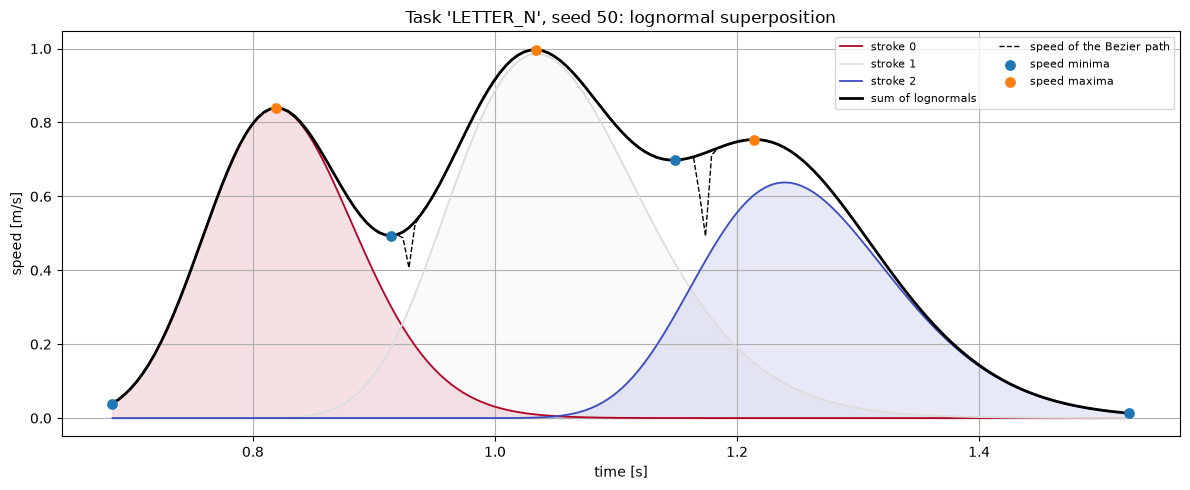

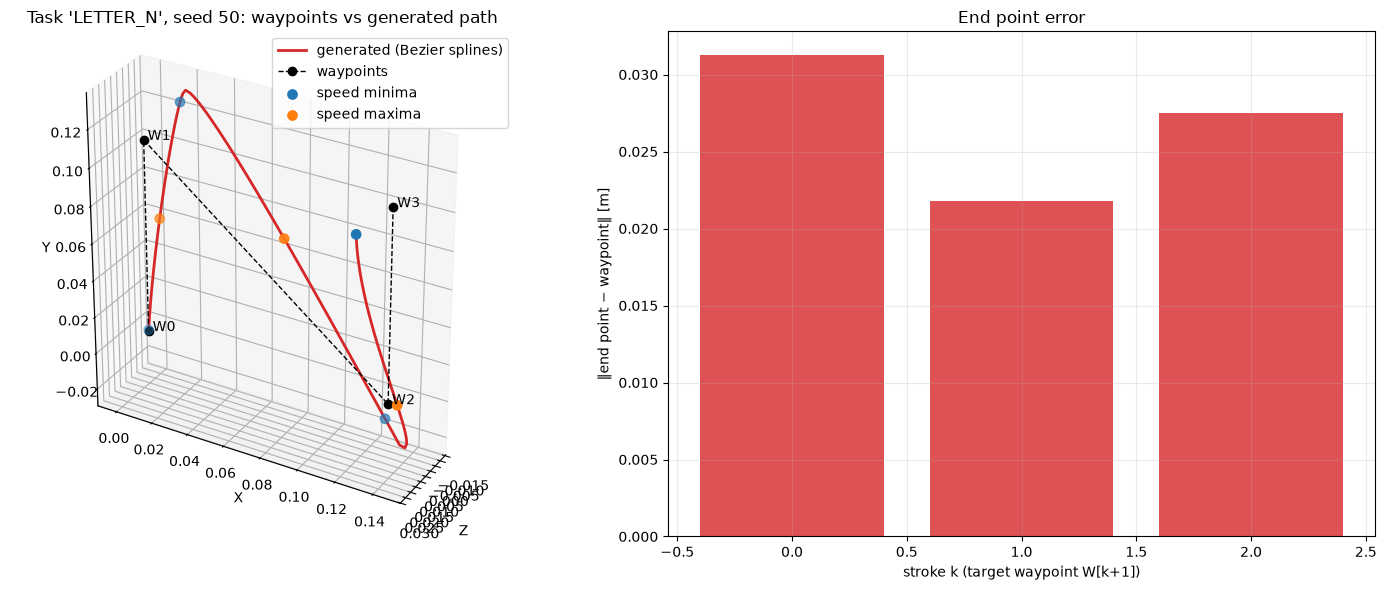

In [ ]:
# model / stats of the best checkpoint: the ones just trained, or reload them from disk
# model, stats, _ = load_checkpoint(CKPT_PATH)

print("tasks:", sorted(WAYPOINTS_BY_TASK))
TASK = "LETTER_N"
SEED = 50
strokes, result = generate_and_plot(model, stats, TASK, SEED, deterministic=False)

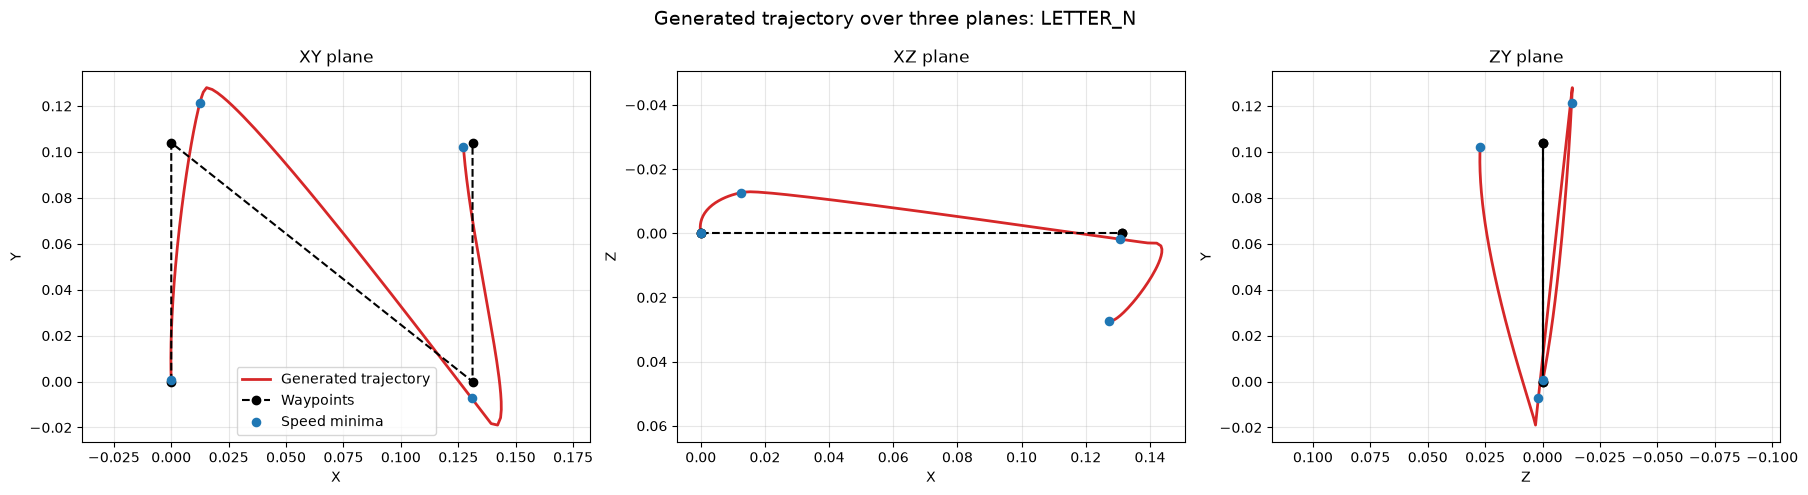

In [ ]:
trajectory = result["points"]
waypoints = WAYPOINTS_BY_TASK[TASK]

planes = [
    (0, 1, "X", "Y", "XY"),
    (0, 2, "X", "Z", "XZ"),
    (2, 1, "Z", "Y", "ZY"),
]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (i, j, xlabel, ylabel, title) in zip(axes, planes):
    ax.plot(
        trajectory[:, i],
        trajectory[:, j],
        color="tab:red",
        linewidth=2,
        label="Generated trajectory",
    )
    ax.plot(
        waypoints[:, i],
        waypoints[:, j],
        "k--o",
        linewidth=1.5,
        markersize=6,
        label="Waypoints",
    )

    ax.scatter(
        trajectory[result["minima"], i],
        trajectory[result["minima"], j],
        color="tab:blue",
        s=35,
        label="Speed minima",
        zorder=3,
    )

    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.set_title(f"{title} plane")
    ax.grid(alpha=0.3)
    ax.axis("equal")

axes[0].legend()
axes[1].invert_yaxis()
axes[2].invert_xaxis()
fig.suptitle(f"Generated trajectory over three planes: {TASK}", fontsize=14)
plt.tight_layout()
plt.show()

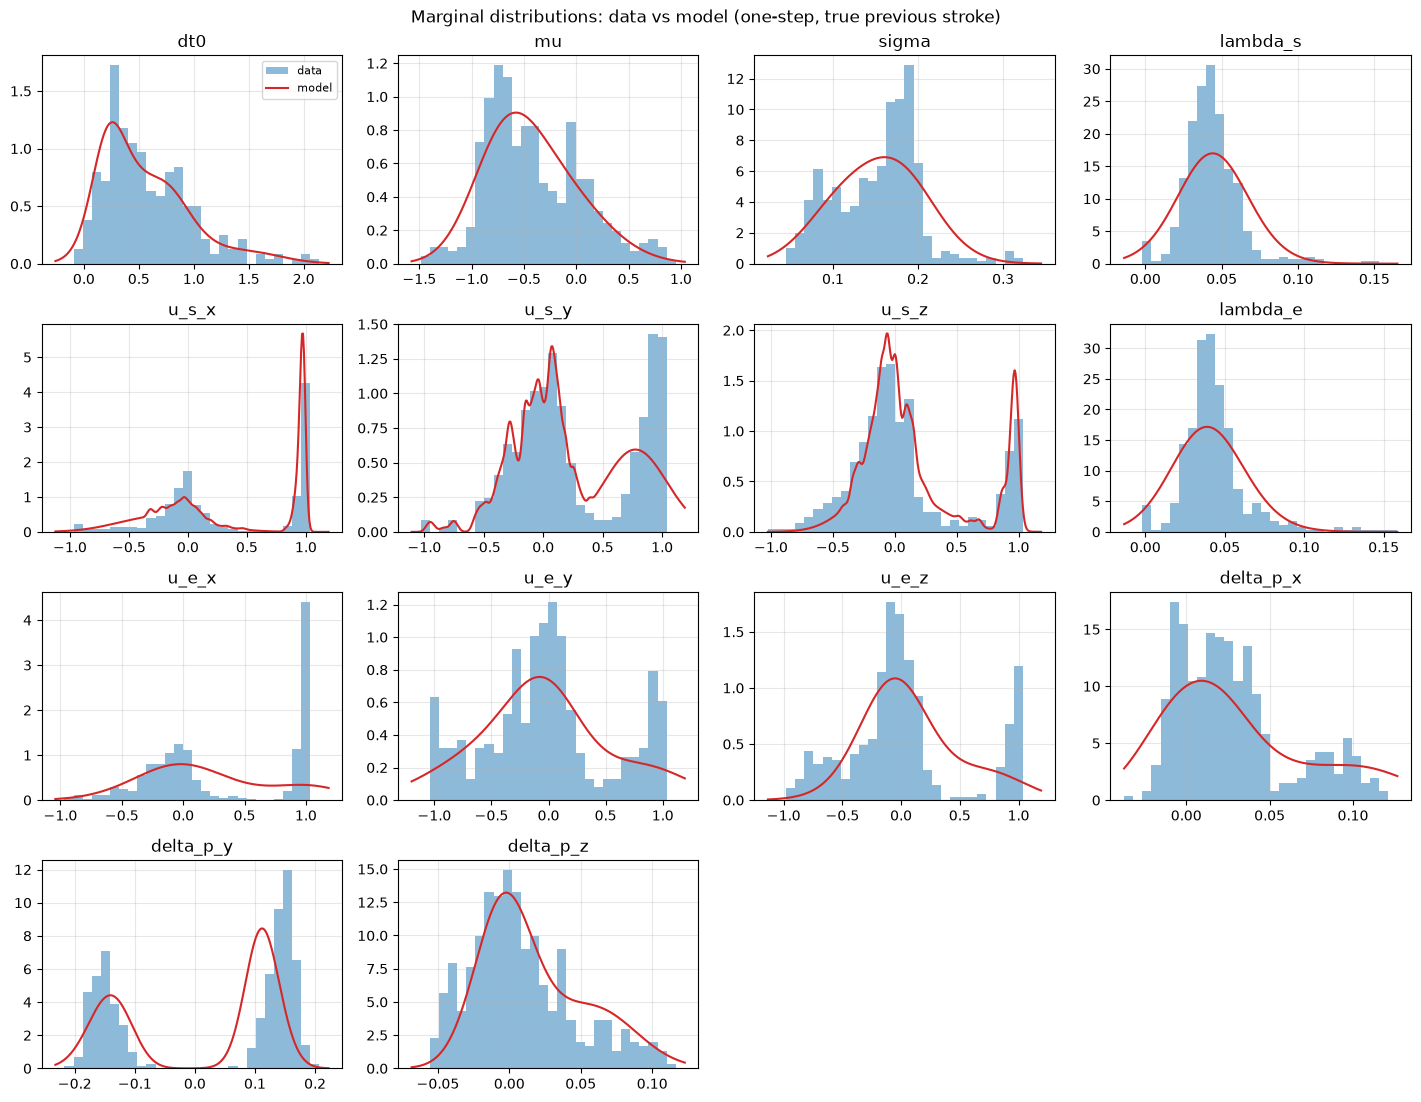

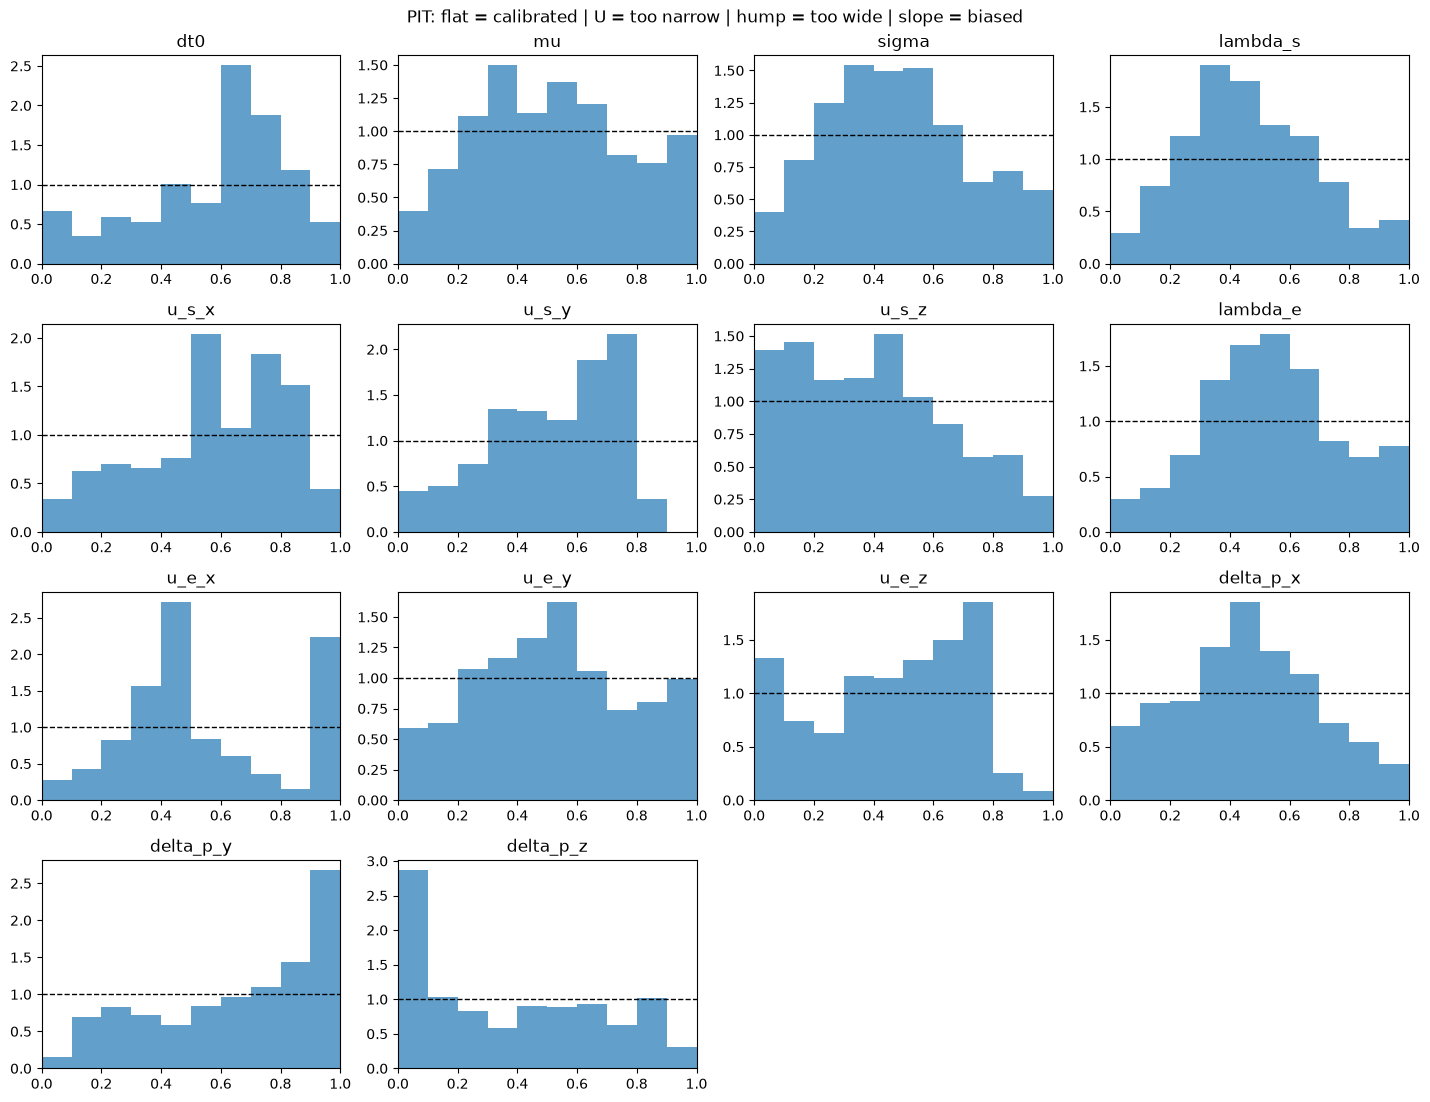

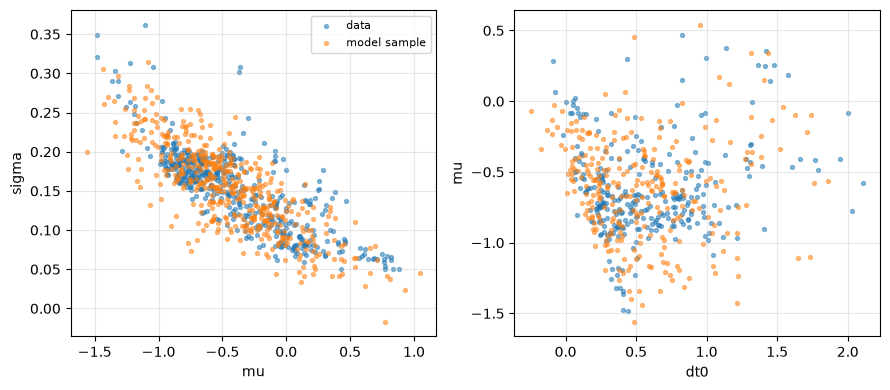

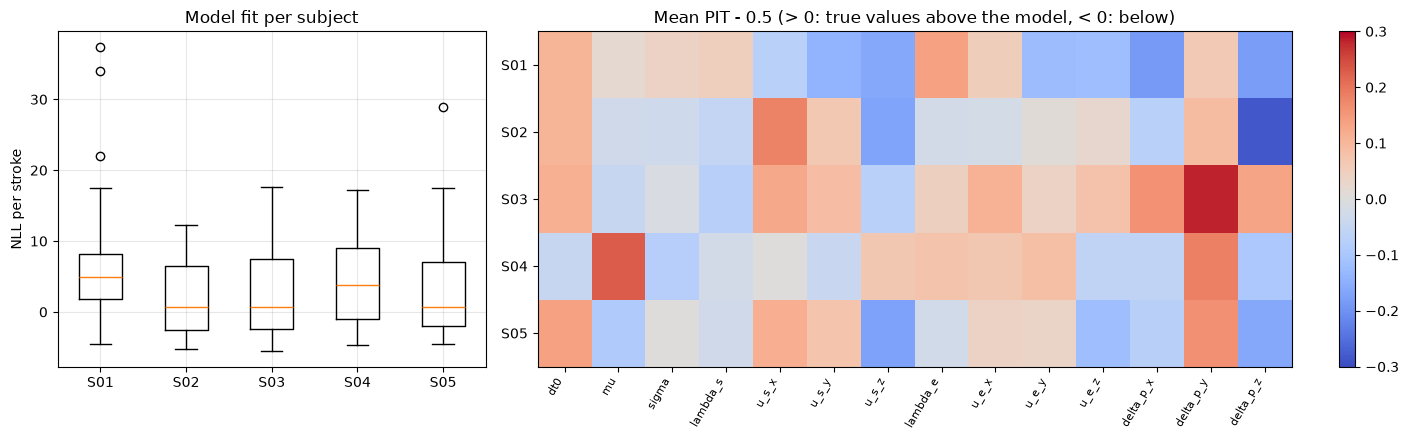

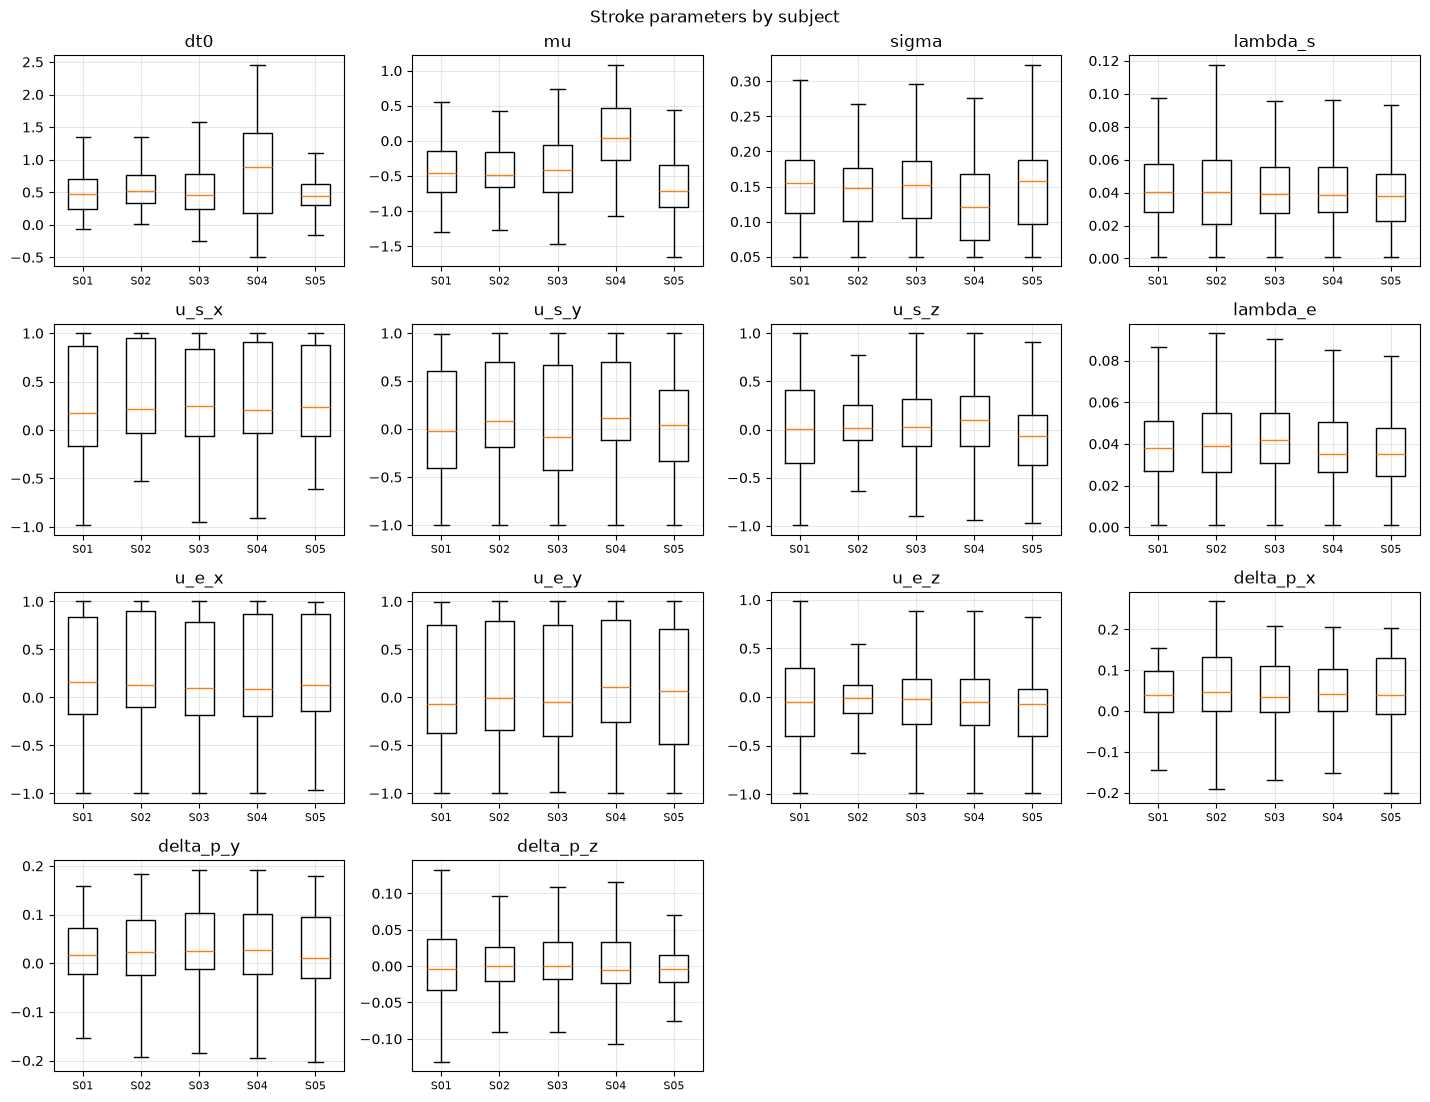

In [ ]:
import matplotlib.pyplot as plt
from torch.distributions import MultivariateNormal

AXES = "xyz"


def output_names():
    """Name of every output dimension, in the order of TARGET_KEYS (vectors get a _x/_y/_z suffix)."""
    names = []
    for key in TARGET_KEYS:
        size = train_ds.tensors[key].size(1)
        names += [key] if size == 1 else [f"{key}_{AXES[i]}" for i in range(size)]
    return names


def _physical_targets(dataset):
    """Targets of a dataset in physical units, concatenated in the order of TARGET_KEYS."""
    n = len(dataset)
    return torch.cat([dataset.tensors[k].float().reshape(n, -1) for k in TARGET_KEYS], dim=1)


def physical_affine(dataset):
    """
    Per-dimension (offset, scale) mapping standardized targets back to physical units.
    The standardization is affine in every dimension, so a least-squares fit recovers it exactly.
    """
    _, _, target_std = model_io(normalize_batch(dataset.tensors, stats, "cpu"), "cpu")
    z, y = target_std.double(), _physical_targets(dataset).double()
    zc, yc = z - z.mean(0), y - y.mean(0)
    scale = (zc * yc).sum(0) / (zc * zc).sum(0)
    offset = y.mean(0) - scale * z.mean(0)
    return offset.numpy(), scale.numpy()


@torch.no_grad()
def predict_mixtures(model, dataset):
    """Predicted mixture (standardized units) and true target of every stroke, with clean inputs (one-step:
    true previous stroke and, for a stateful model, the true history of the recording in the state)."""
    model.eval()
    batch = normalize_batch(dataset.tensors, stats, device)
    _, _, target = model_io(batch, device)
    means, scale_tril, logits = forward_dataset(model, dataset, batch)
    pred = dict(
        means=means, scale_tril=scale_tril, logits=logits, target=target,
        weights=torch.softmax(logits, dim=-1),
        stds=scale_tril.pow(2).sum(-1).sqrt(),    # marginal std of each dimension: sqrt(diag(L L^T))
        is_first=batch["is_first"],
    )
    return {k: v.cpu() for k, v in pred.items()}


def pit_values(pred):
    """Probability integral transform: marginal CDF of the predicted mixture at the true value, [N, D].
    The dt0 entry of the first strokes is NaN (it is a constant, not data)."""
    z = (pred["target"].unsqueeze(1) - pred["means"]) / pred["stds"]
    cdf = 0.5 * (1.0 + torch.erf(z / np.sqrt(2.0)))
    pit = (pred["weights"].unsqueeze(-1) * cdf).sum(1).numpy()
    pit[pred["is_first"].numpy().reshape(-1) > 0.5, DT0_INDEX] = np.nan
    return pit


def per_sample_nll(pred):
    """Mixture NLL of every stroke (standardized units); dt0 is ignored for first strokes."""
    log_joint = torch.log_softmax(pred["logits"], dim=-1) + component_log_prob(
        pred["means"], pred["scale_tril"], pred["target"], pred["is_first"]
    )
    return -torch.logsumexp(log_joint, dim=-1).numpy()


def sample_from(pred, seed=0):
    """One sample of the predicted mixture for every stroke (standardized units)."""
    g = torch.Generator().manual_seed(seed)
    comp = torch.multinomial(pred["weights"], 1, generator=g).squeeze(-1)
    idx = torch.arange(len(comp))
    eps = torch.randn(len(comp), pred["means"].size(-1), generator=g)
    return (pred["means"][idx, comp] + (pred["scale_tril"][idx, comp] @ eps.unsqueeze(-1)).squeeze(-1)).numpy()


def _grid(n_panels, n_cols=4, width=3.6, height=2.8):
    n_rows = int(np.ceil(n_panels / n_cols))
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(width * n_cols, height * n_rows), squeeze=False)
    for ax in axes.ravel()[n_panels:]:
        ax.axis("off")
    return fig, axes.ravel()


def plot_marginals(pred, names, affine, n_grid=300):
    """Histogram of the true values against the model marginal density, averaged over the conditions.
    dt0 is evaluated only on the strokes that are not the first of their recording."""
    offset, scale = affine
    real = pred["target"].numpy() * scale + offset
    weights = pred["weights"].numpy()
    later = pred["is_first"].numpy().reshape(-1) < 0.5
    fig, axes = _grid(len(names))
    for i, (ax, name) in enumerate(zip(axes, names)):
        rows = later if i == DT0_INDEX else np.ones(len(real), dtype=bool)
        rows_t = torch.from_numpy(rows)
        low, high = np.percentile(real[rows, i], [0.5, 99.5])
        pad = 0.1 * (high - low)
        grid = np.linspace(low - pad, high + pad, n_grid)
        grid_std = (grid - offset[i]) / scale[i]
        mu = pred["means"][rows_t][:, :, i].numpy()[..., None]
        sd = pred["stds"][rows_t][:, :, i].numpy()[..., None]
        pdf = np.exp(-0.5 * ((grid_std - mu) / sd) ** 2) / (sd * np.sqrt(2.0 * np.pi))
        density = (weights[rows][..., None] * pdf).sum(1).mean(0) / abs(scale[i])
        ax.hist(real[rows, i], bins=30, range=(grid[0], grid[-1]), density=True, alpha=0.5, label="data")
        ax.plot(grid, density, color="tab:red", label="model")
        ax.set_title(name)
        ax.grid(alpha=0.3)
    axes[0].legend(fontsize=8)
    fig.suptitle("Marginal distributions: data vs model (one-step, true previous stroke)")
    plt.tight_layout()
    plt.show()


def plot_pit(pit, names, bins=10):
    """PIT histograms: flat = calibrated, U shape = too narrow, hump = too wide, slope = biased."""
    fig, axes = _grid(len(names))
    for i, (ax, name) in enumerate(zip(axes, names)):
        values = pit[:, i][~np.isnan(pit[:, i])]
        ax.hist(values, bins=bins, range=(0.0, 1.0), density=True, alpha=0.7)
        ax.axhline(1.0, color="black", linestyle="--", linewidth=1)
        ax.set_xlim(0.0, 1.0)
        ax.set_title(name)
    fig.suptitle("PIT: flat = calibrated | U = too narrow | hump = too wide | slope = biased")
    plt.tight_layout()
    plt.show()


def plot_pairs(pred, names, affine, pairs):
    """Joint structure of pairs of parameters: data against one model sample per condition.
    dt0 is shown only for the strokes that are not the first of their recording."""
    offset, scale = affine
    real = pred["target"].numpy() * scale + offset
    fake = sample_from(pred) * scale + offset
    later = pred["is_first"].numpy().reshape(-1) < 0.5
    fig, axes = plt.subplots(1, len(pairs), figsize=(4.5 * len(pairs), 4), squeeze=False)
    for ax, (a, b) in zip(axes[0], pairs):
        i, j = names.index(a), names.index(b)
        rows = later if DT0_INDEX in (i, j) else np.ones(len(real), dtype=bool)
        ax.scatter(real[rows, i], real[rows, j], s=8, alpha=0.5, label="data")
        ax.scatter(fake[rows, i], fake[rows, j], s=8, alpha=0.5, label="model sample")
        ax.set_xlabel(a)
        ax.set_ylabel(b)
        ax.grid(alpha=0.3)
    axes[0, 0].legend(fontsize=8)
    plt.tight_layout()
    plt.show()


def plot_subject_fit(pred, names, subjects):
    """Per subject: NLL distribution, and mean PIT - 0.5 per parameter (sign = systematic bias of the model)."""
    nll, pit = per_sample_nll(pred), pit_values(pred)
    levels = sorted(np.unique(subjects))
    fig, (ax_nll, ax_bias) = plt.subplots(1, 2, figsize=(15, 4.5), gridspec_kw={"width_ratios": [1, 2.2]})

    ax_nll.boxplot([nll[subjects == s] for s in levels])
    ax_nll.set_xticks(range(1, len(levels) + 1))
    ax_nll.set_xticklabels(levels)
    ax_nll.set_ylabel("NLL per stroke")
    ax_nll.set_title("Model fit per subject")
    ax_nll.grid(alpha=0.3)

    bias = np.array([np.nanmean(pit[subjects == s], axis=0) - 0.5 for s in levels])
    image = ax_bias.imshow(bias, cmap="coolwarm", vmin=-0.3, vmax=0.3, aspect="auto")
    ax_bias.set_xticks(range(len(names)))
    ax_bias.set_xticklabels(names, rotation=60, ha="right", fontsize=8)
    ax_bias.set_yticks(range(len(levels)))
    ax_bias.set_yticklabels(levels)
    ax_bias.set_title("Mean PIT - 0.5 (> 0: true values above the model, < 0: below)")
    fig.colorbar(image, ax=ax_bias)
    plt.tight_layout()
    plt.show()


def plot_parameters_by_subject(dataset, subjects, names):
    """Distribution of every target parameter for each subject, in physical units (data only).
    dt0 is shown only for the strokes that are not the first of their recording."""
    values = _physical_targets(dataset).numpy()
    later = dataset.tensors["is_first"].numpy().reshape(-1) < 0.5
    levels = sorted(np.unique(subjects))
    fig, axes = _grid(len(names))
    for i, (ax, name) in enumerate(zip(axes, names)):
        rows = later if i == DT0_INDEX else np.ones(len(values), dtype=bool)
        ax.boxplot([values[rows & (subjects == s), i] for s in levels], showfliers=False)
        ax.set_xticks(range(1, len(levels) + 1))
        ax.set_xticklabels(levels, fontsize=8)
        ax.set_title(name)
        ax.grid(alpha=0.3)
    fig.suptitle("Stroke parameters by subject")
    plt.tight_layout()
    plt.show()


# ---- usage ----
names = output_names()
pred = predict_mixtures(model, val_ds)
affine = physical_affine(val_ds)
plot_marginals(pred, names, affine)
plot_pit(pit_values(pred), names)
plot_pairs(pred, names, affine, pairs=[("mu", "sigma"), ("dt0", "mu")])
plot_subject_fit(pred, names, val_df["subject"].to_numpy())
plot_parameters_by_subject(StrokeDataset(formatted_data), formatted_data["subject"].to_numpy(), names)

## Real vs generated stroke parameters
Cell 1: data collection and helper functions. Cell 2: pair matrix. Cell 3: PCA and separability test.

In [ ]:
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from matplotlib.lines import Line2D

COMPARE_TASK = TASK        # task whose strokes are compared
COMPARE_STROKE = 0         # stroke index to compare; None pools every stroke after the first (their dt0 is a measured delay)
N_SYNTHETIC = None         # number of generated sequences (one seed each); None = number of recorded trials
HIGHLIGHT_SEED = SEED      # generated sample drawn as a star in every plot

PARAM_NAMES = output_names()


def keep_stroke(number, wanted):
    """True if the stroke index `number` is selected: `wanted` is a stroke index, or None for every stroke after the first."""
    return number >= 1 if wanted is None else number == wanted


def params_to_vector(params):
    """Concatenate the target parameters of one stroke in the order of TARGET_KEYS (physical units)."""
    return np.concatenate([np.atleast_1d(np.asarray(params[key], dtype=np.float64)).ravel() for key in TARGET_KEYS])


def real_parameters(task, stroke_number=None):
    """Parameter vectors [N, D] of the recorded strokes of a task (all subjects and recordings)."""
    mask = formatted_data["task"] == task
    mask &= formatted_data["stroke_number"].astype(int).apply(lambda n: keep_stroke(n, stroke_number))
    return np.stack([params_to_vector(row) for _, row in formatted_data[mask].iterrows()])


def synthetic_parameters(task, n_sequences, stroke_number=None, first_seed=0):
    """Parameter vectors [N, D] of generated strokes: one autoregressive sequence per seed."""
    vectors = []
    for seed in range(first_seed, first_seed + n_sequences):
        for stroke in generate_task(model, stats, task, seed):
            if keep_stroke(stroke["stroke_number"], stroke_number):
                vectors.append(params_to_vector(stroke))
    return np.stack(vectors)


def set_axes_equal(ax, points, margin=0.05):
    """Give the 3D axes the same metric scale, centered on the given (N, 3) points."""
    mins, maxs = points.min(axis=0), points.max(axis=0)
    centers = (mins + maxs) / 2
    half_span = (maxs - mins).max() / 2 * (1 + margin)
    ax.set_xlim(centers[0] - half_span, centers[0] + half_span)
    ax.set_ylim(centers[1] - half_span, centers[1] + half_span)
    ax.set_zlim(centers[2] - half_span, centers[2] + half_span)
    ax.set_box_aspect((1, 1, 1))


def plot_pair_matrix(real, synthetic, highlight, names, title=""):
    """
    Lower-triangular scatter matrix of every pair of variables.
    Red: recorded strokes. Blue: generated strokes. Star: highlighted generated sample.
    Diagonal: marginal histograms, with the highlighted sample as a vertical line.
    """
    n = len(names)
    fig, axes = plt.subplots(n, n, figsize=(1.8 * n, 1.8 * n), squeeze=False)
    for i in range(n):
        for j in range(n):
            ax = axes[i, j]
            if j > i:
                ax.axis("off")
                continue
            if i == j:
                low = min(real[:, i].min(), synthetic[:, i].min())
                high = max(real[:, i].max(), synthetic[:, i].max())
                bins = np.linspace(low, high + 1e-12, 25)
                ax.hist(real[:, i], bins=bins, density=True, color="tab:red", alpha=0.5)
                ax.hist(synthetic[:, i], bins=bins, density=True, color="tab:blue", alpha=0.5)
                for value in highlight[:, i]:
                    ax.axvline(value, color="black", linewidth=1.2)
            else:
                ax.scatter(real[:, j], real[:, i], s=6, alpha=0.5, color="tab:red", linewidths=0)
                ax.scatter(synthetic[:, j], synthetic[:, i], s=6, alpha=0.35, color="tab:blue", linewidths=0)
                ax.scatter(highlight[:, j], highlight[:, i], marker="*", s=90, color="tab:blue",
                           edgecolor="black", linewidths=0.8, zorder=5)
            ax.tick_params(labelsize=6, labelbottom=(i == n - 1), labelleft=(j == 0 and i > 0))
            if i == n - 1:
                ax.set_xlabel(names[j], fontsize=8)
            if j == 0 and i > 0:
                ax.set_ylabel(names[i], fontsize=8)

    handles = [
        Line2D([], [], marker="o", linestyle="", color="tab:red", label="recorded"),
        Line2D([], [], marker="o", linestyle="", color="tab:blue", label="generated"),
        Line2D([], [], marker="*", linestyle="", markersize=12, markerfacecolor="tab:blue",
               markeredgecolor="black", label=f"highlighted sample (seed {HIGHLIGHT_SEED})"),
    ]
    fig.legend(handles=handles, loc="upper right", bbox_to_anchor=(0.97, 0.97))
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()


def fit_projection(real, synthetic, n_components, fit_on="real"):
    """Standardization followed by PCA, fitted on the recorded strokes ("real") or on both sets ("both")."""
    reference = real if fit_on == "real" else np.vstack([real, synthetic])
    return make_pipeline(StandardScaler(), PCA(n_components=n_components)).fit(reference)


def plot_pca(pca, z_real, z_synth, z_high, title=""):
    """Projected strokes: 1 component -> histogram, 2 -> scatter, 3 -> 3D scatter, more -> scatter matrix."""
    n = z_real.shape[1]
    labels = [f"PC{k + 1} ({r:.0%})" for k, r in enumerate(pca.explained_variance_ratio_)]
    if n > 3:
        plot_pair_matrix(z_real, z_synth, z_high, labels, title=title)
        return

    fig = plt.figure(figsize=(8, 6))
    ax = fig.add_subplot(projection="3d") if n == 3 else fig.add_subplot()
    if n == 1:
        bins = np.linspace(min(z_real.min(), z_synth.min()), max(z_real.max(), z_synth.max()) + 1e-12, 30)
        ax.hist(z_real[:, 0], bins=bins, density=True, color="tab:red", alpha=0.5, label="recorded")
        ax.hist(z_synth[:, 0], bins=bins, density=True, color="tab:blue", alpha=0.5, label="generated")
        for value in z_high[:, 0]:
            ax.axvline(value, color="black", linewidth=1.5)
        ax.set_xlabel(labels[0])
    else:
        ax.scatter(*z_real.T, s=14, alpha=0.5, color="tab:red", label="recorded")
        ax.scatter(*z_synth.T, s=14, alpha=0.35, color="tab:blue", label="generated")
        ax.scatter(*z_high.T, marker="*", s=180, color="tab:blue", edgecolor="black", zorder=5,
                   label=f"highlighted sample (seed {HIGHLIGHT_SEED})")
        ax.set_xlabel(labels[0])
        ax.set_ylabel(labels[1])
        if n == 3:
            ax.set_zlabel(labels[2])
            set_axes_equal(ax, np.vstack([z_real, z_synth, z_high]))
        else:
            ax.set_aspect("equal")
    ax.set_title(title)
    ax.legend()
    plt.tight_layout()
    plt.show()


CLASSIFIERS = {
    "logistic regression": LogisticRegression(class_weight="balanced", max_iter=1000),
    "random forest": RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=0),
}


def separability(z_real, z_synth, seed=0):
    """
    Cross-validated ROC AUC of classifiers that separate recorded (label 0) from generated (label 1) strokes.
    0.5 = the classifier cannot tell them apart, 1.0 = perfectly separable.
    """
    x = np.vstack([z_real, z_synth])
    y = np.r_[np.zeros(len(z_real)), np.ones(len(z_synth))]
    folds = min(5, len(z_real), len(z_synth))
    cv = StratifiedKFold(n_splits=folds, shuffle=True, random_state=seed)
    return {
        name: roc_auc_score(y, cross_val_predict(clf, x, y, cv=cv, method="predict_proba")[:, 1])
        for name, clf in CLASSIFIERS.items()
    }


# Recorded and generated strokes of the task, plus the highlighted generated sample (same task and seed as before).
real = real_parameters(COMPARE_TASK, COMPARE_STROKE)
if N_SYNTHETIC is None:
    N_SYNTHETIC = formatted_data.loc[formatted_data["task"] == COMPARE_TASK, ["subject", "recording"]].drop_duplicates().shape[0]
synthetic = synthetic_parameters(COMPARE_TASK, N_SYNTHETIC, COMPARE_STROKE)
highlight = np.stack([
    params_to_vector(s) for s in generate_task(model, stats, COMPARE_TASK, HIGHLIGHT_SEED)
    if keep_stroke(s["stroke_number"], COMPARE_STROKE)
])

# Variables that are constant in both sets (e.g. dt0 of the first stroke) carry no information and are dropped.
varying = np.ptp(np.vstack([real, synthetic]), axis=0) > 0
real, synthetic, highlight = real[:, varying], synthetic[:, varying], highlight[:, varying]
PARAM_NAMES = [name for name, keep in zip(PARAM_NAMES, varying) if keep]

print(f"task '{COMPARE_TASK}': {int((train_df['task'] == COMPARE_TASK).sum())} strokes in training, "
      f"{int((val_df['task'] == COMPARE_TASK).sum())} in validation")
print(f"recorded: {len(real)} strokes | generated: {len(synthetic)} strokes | highlighted: {len(highlight)}")


In [ ]:
# Pair matrix of the stroke parameters; use a subset of PARAM_NAMES to get a smaller matrix.
PAIR_FEATURES = PARAM_NAMES
columns = [PARAM_NAMES.index(name) for name in PAIR_FEATURES]
stroke_label = "strokes after the first" if COMPARE_STROKE is None else f"stroke {COMPARE_STROKE}"
plot_pair_matrix(
    real[:, columns], synthetic[:, columns], highlight[:, columns], PAIR_FEATURES,
    title=f"{COMPARE_TASK}, {stroke_label}: recorded vs generated parameters",
)


In [ ]:
# PCA on the standardized parameters, with a variable number of components.
N_COMPONENTS = 3           # 1 -> histogram | 2 -> 2D | 3 -> 3D | > 3 -> scatter matrix of the components
PCA_FIT_ON = "real"        # "real": axes of the recorded strokes | "both": axes of the pooled strokes

projection = fit_projection(real, synthetic, N_COMPONENTS, PCA_FIT_ON)
pca = projection[-1]
z_real, z_synth, z_high = (projection.transform(x) for x in (real, synthetic, highlight))

plot_pca(
    pca, z_real, z_synth, z_high,
    title=f"{COMPARE_TASK}, {stroke_label}: PCA with {N_COMPONENTS} components "
          f"({pca.explained_variance_ratio_.sum():.0%} of the variance)",
)

# Separability of the two sets: on the PCA components and on the full standardized space.
scaler = projection[0]
print("ROC AUC, recorded vs generated (cross-validated; 0.5 = indistinguishable)")
for name, auc in separability(z_real, z_synth).items():
    print(f"  {N_COMPONENTS} components    | {name:20s} | {auc:.3f}")
for name, auc in separability(scaler.transform(real), scaler.transform(synthetic)).items():
    print(f"  all {real.shape[1]} parameters | {name:20s} | {auc:.3f}")
